In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
import logging

LOG_DIR = "../logs"
os.makedirs(LOG_DIR, exist_ok=True)

logging.basicConfig(
    filename=os.path.join(LOG_DIR, "eda_log.txt"),
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)

logger = logging.getLogger(__name__)

logger.info("EDA process started")

In [3]:
BASE_DIR = os.path.abspath("..")

OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

# Load merged training dataset
train_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "train_merged.csv"),
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)

# Load merged testing dataset
test_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "test_merged.csv"),
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)

print("Merged datasets loaded successfully!")
logger.info("Data loaded successfully")

Merged datasets loaded successfully!


In [4]:
train_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,NaN,0,"1,270.00"
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct",0,570.00
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct",0,"14,130.00"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,"2,009.00",0,0.00,0.00,NaN,0,620.00
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,"16,107.50",4.00,"2,015.00",0,0.00,0.00,NaN,0,"29,910.00"


In [5]:
test_df.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,1,4,2015-09-17,1.00,1,0,0,c,a,"1,270.00",9.00,"2,008.00",0,0.00,0.00,NaN,0,"1,270.00"
1,2,3,4,2015-09-17,1.00,1,0,0,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct",0,"14,130.00"
2,3,7,4,2015-09-17,1.00,1,0,0,a,c,"16,107.50",4.00,"2,013.00",0,0.00,0.00,NaN,0,"24,000.00"
3,4,8,4,2015-09-17,1.00,1,0,0,a,a,"7,520.00",10.00,"2,014.00",0,0.00,0.00,NaN,0,"7,520.00"
4,5,9,4,2015-09-17,1.00,1,0,0,a,c,"2,030.00",8.00,"2,000.00",0,0.00,0.00,NaN,0,"2,030.00"


In [6]:
print(train_df.info())
print(test_df.info())
logger.info("Understanding the Training & test Dataset Completed")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 20 columns):
 #   Column                        Non-Null Count    Dtype         
---  ------                        --------------    -----         
 0   Store                         1017209 non-null  int64         
 1   DayOfWeek                     1017209 non-null  int64         
 2   Date                          1017209 non-null  datetime64[ns]
 3   Sales                         1017209 non-null  int64         
 4   Customers                     1017209 non-null  int64         
 5   Open                          1017209 non-null  int64         
 6   Promo                         1017209 non-null  int64         
 7   StateHoliday                  1017209 non-null  string        
 8   SchoolHoliday                 1017209 non-null  int64         
 9   StoreType                     1017209 non-null  object        
 10  Assortment                    1017209 non-null  object        
 11

In [7]:
print("Duplicate rows in train_df:", train_df.duplicated().sum())
print("Duplicate rows in test_df:", test_df.duplicated().sum())
logger.info("Duplicate row analysis completed")

Duplicate rows in train_df: 0
Duplicate rows in test_df: 0


In [8]:
print("Missing values in train_df:", train_df.isnull().sum())
print("Missing values in test_df:", test_df.isnull().sum())
logger.info("Missing value analysis completed")

Missing values in train_df: Store                                0
DayOfWeek                            0
Date                                 0
Sales                                0
Customers                            0
Open                                 0
Promo                                0
StateHoliday                         0
SchoolHoliday                        0
StoreType                            0
Assortment                           0
CompetitionDistance                  0
CompetitionOpenSinceMonth            0
CompetitionOpenSinceYear             0
Promo2                               0
Promo2SinceWeek                      0
Promo2SinceYear                      0
PromoInterval                   508031
CompetitionOpenDateMissing           0
CompetitionDistance_Original         0
dtype: int64
Missing values in test_df: Id                                  0
Store                               0
DayOfWeek                           0
Date                                0


In [9]:
# Check Promo2 distribution
print(train_df["Promo2"].value_counts())
print(test_df["Promo2"].value_counts())

Promo2
1    509178
0    508031
Name: count, dtype: int64
Promo2
1    23856
0    17232
Name: count, dtype: int64


In [10]:
print(pd.crosstab(
    train_df["Promo2"],
    train_df["PromoInterval"].isnull(),
    margins=True
))

print(pd.crosstab(
    test_df["Promo2"],
    test_df["PromoInterval"].isnull(),
    margins=True
))

PromoInterval   False    True      All
Promo2                                
0                   0  508031   508031
1              509178       0   509178
All            509178  508031  1017209
PromoInterval  False   True    All
Promo2                            
0                  0  17232  17232
1              23856      0  23856
All            23856  17232  41088


In [11]:
train_df["PromoInterval"] = train_df["PromoInterval"].fillna("No Promo2")

test_df["PromoInterval"] = test_df["PromoInterval"].fillna("No Promo2")

In [12]:
print(train_df["PromoInterval"].isnull().sum())
print(test_df["PromoInterval"].isnull().sum())

0
0


+ The PromoInterval column contains 508,031 missing values in train_df dataset and 17,232 missing values in test_df dataset. After analyzing its relationship with Promo2, it was observed that all missing values belong to stores where Promo2 = 0. This indicates that these stores do not participate in the Promo2 promotional program and therefore have no promotion interval. Since these missing values represent meaningful information rather than data errors, they were replaced with the categorical value "No Promo2" instead of deleting the records inn both datasets.

In [13]:
display(train_df.describe().T)
logger.info("Statistical Analysis of training dataset completed")

,count,mean,min,25%,50%,75%,max,std
Store,"1,017,209.00",558.43,1.00,280.00,558.00,838.00,"1,115.00",321.91
DayOfWeek,"1,017,209.00",4.00,1.00,2.00,4.00,6.00,7.00,2.00
Date,1017209,2014-04-11 01:30:42.846061824,2013-01-01 00:00:00,2013-08-17 00:00:00,2014-04-02 00:00:00,2014-12-12 00:00:00,2015-07-31 00:00:00,NaN
Sales,"1,017,209.00","5,773.82",0.00,"3,727.00","5,744.00","7,856.00","41,551.00","3,849.93"
Customers,"1,017,209.00",633.15,0.00,405.00,609.00,837.00,"7,388.00",464.41
Open,"1,017,209.00",0.83,0.00,1.00,1.00,1.00,1.00,0.38
Promo,"1,017,209.00",0.38,0.00,0.00,0.00,1.00,1.00,0.49
SchoolHoliday,"1,017,209.00",0.18,0.00,0.00,0.00,0.00,1.00,0.38
CompetitionDistance,"1,017,209.00","4,644.64",20.00,710.00,"2,325.00","6,880.00","16,107.50","5,188.99"
CompetitionOpenSinceMonth,"1,017,209.00",4.93,0.00,0.00,4.00,9.00,12.00,4.28


In [14]:
print("Open Stores:", (train_df["Open"] == 1).sum())
print("Closed Stores:", (train_df["Open"] == 0).sum())

Open Stores: 844392
Closed Stores: 172817


In [15]:
print("Open Stores:", (test_df["Open"] == 1).sum())
print("Closed Stores:", (test_df["Open"] == 0).sum())

Open Stores: 35104
Closed Stores: 5984


In [16]:
print("Total Sales:", train_df["Sales"].sum())

print("Average Sales:", train_df["Sales"].mean())

print("Maximum Sales:", train_df["Sales"].max())

print("Minimum Sales:", train_df["Sales"].min())
logger.info("Sales statistical analysis completed")

Total Sales: 5873180623
Average Sales: 5773.818972305593
Maximum Sales: 41551
Minimum Sales: 0


### Insight
+ Total Sales: The total sales across all records amount to approximately 5.87 billion, indicating a substantial volume of business generated across Rossmann stores during the training period.
+ Average Sales: The average sales value is approximately 5,774 per record, suggesting that stores generate around 5,774 in sales per recorded observation.
+ Maximum Sales: The highest recorded sales value is 41,551, indicating that some store-day observations experience significantly higher sales than the average.
+ Minimum Sales: The minimum sales value is 0, which may correspond to stores that were closed on particular days or had no recorded sales.
+ Variation in Sales: The considerable difference between minimum and maximum sales suggests substantial variation in sales across different stores and dates.

In [17]:
train_df[train_df["Sales"] == 0]["Open"].value_counts(dropna=False)

Open
0    172817
1        54
Name: count, dtype: int64

In [18]:
# Modern visualization theme
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="viridis"
)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.titleweight"] = "bold"

plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.labelweight"] = "medium"

plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [19]:
def add_bar_labels(ax, fmt="{:,.0f}"):

    for container in ax.containers:

        labels = [
            fmt.format(bar.get_height())
            if pd.notna(bar.get_height()) else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=4,
            fontsize=9,
            fontweight="bold"
        )

## Sales Distribution

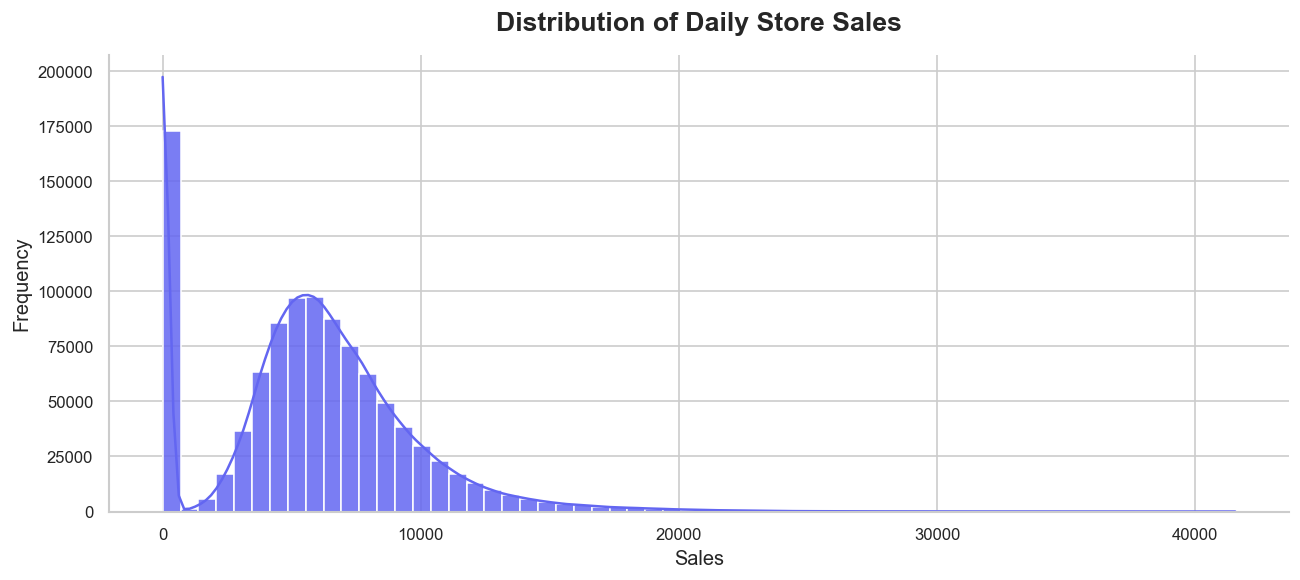

In [20]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=train_df,
    x="Sales",
    bins=60,
    kde=True,
    color="#6366F1",
    edgecolor="white",
    alpha=0.85
)

plt.title("Distribution of Daily Store Sales", pad=15)
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Insight
+ The sales distribution is right-skewed, indicating that most store-day records have sales within a relatively moderate range, while a smaller number of records show very high sales.
+ The presence of high-value observations indicates considerable variation in daily sales across stores.
+ The distribution suggests that sales are not uniform across all stores and dates. Store characteristics, promotions, holidays, and seasonal factors may contribute to these differences.

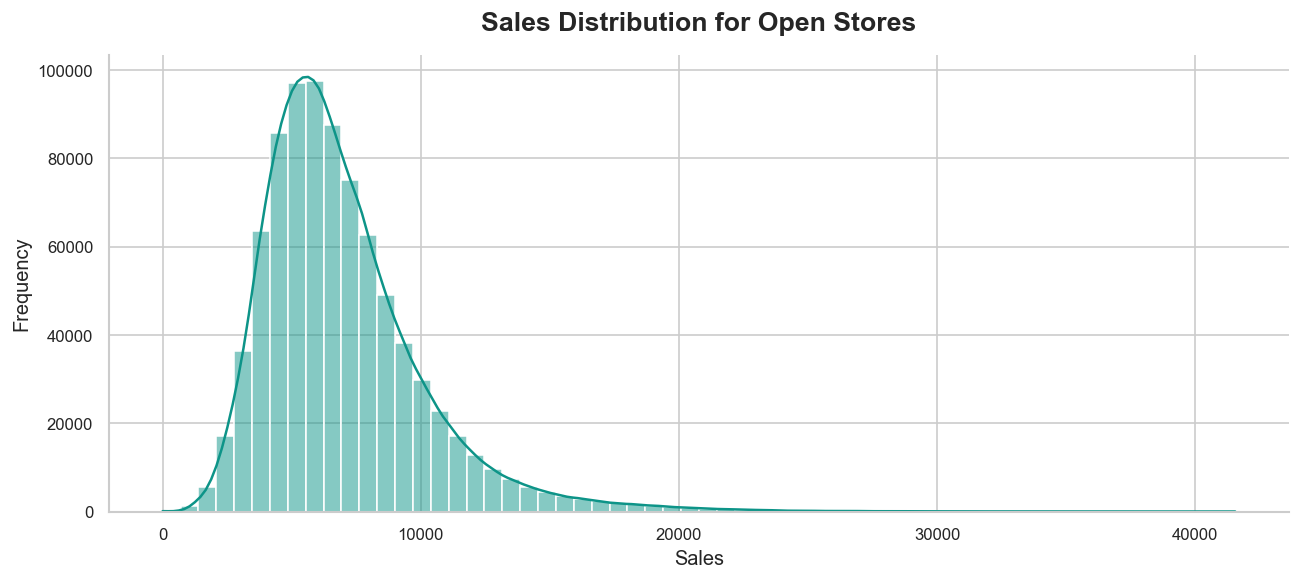

In [21]:
open_train = train_df[train_df["Open"] == 1].copy()

plt.figure(figsize=(11, 5))

sns.histplot(
    data=open_train,
    x="Sales",
    bins=60,
    kde=True,
    color="#0D9488",
    edgecolor="white"
)

plt.title("Sales Distribution for Open Stores", pad=15)
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
logger.info("Sales distribution analysis completed")

### Insight
+ After filtering out closed stores, the distribution focuses on actual business activity.
+ Sales values are concentrated around the common daily sales range, with fewer observations at the higher end.
+ This plot provides a more meaningful view of sales performance because closed-store records with zero sales are excluded.
+ The difference between the overall and open-store distributions highlights why sales analysis should generally be performed using records where Open = 1.

## Customer Distribution

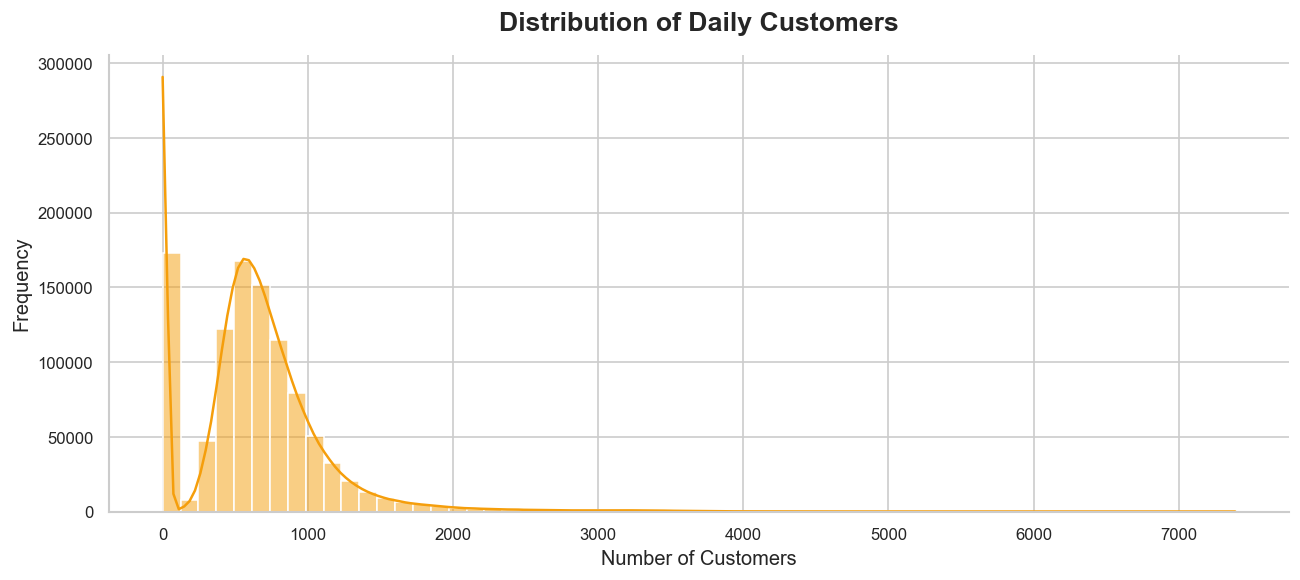

In [22]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=train_df,
    x="Customers",
    bins=60,
    kde=True,
    color="#F59E0B",
    edgecolor="white"
)

plt.title("Distribution of Daily Customers", pad=15)
plt.xlabel("Number of Customers")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
logger.info("Customer distribution analysis completed")

### Insight
+ Customer counts are right-skewed, showing that most store-day records have a moderate number of customers, while some stores experience considerably higher footfall.
+ The variation in customer numbers suggests differences in store size, location, popularity, and customer demand.
+ Some records contain zero customers, which may correspond to stores that were closed.
+ Customer footfall is an important factor to examine because it is likely to influence daily sales.

## Store Type Distribution

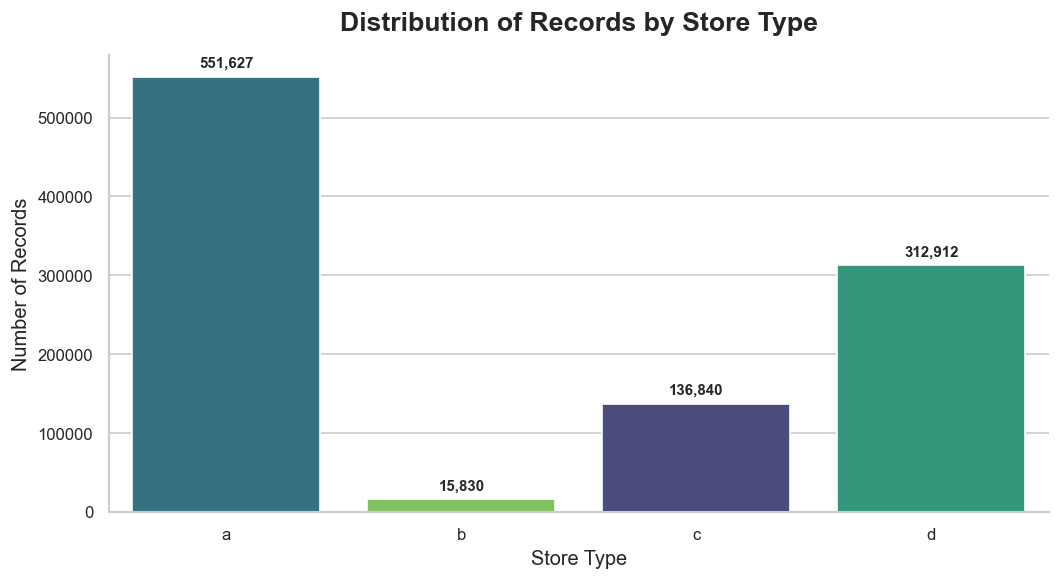

In [23]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=train_df,
    x="StoreType",
    hue="StoreType",
    palette="viridis",
    legend=False,
    order=sorted(train_df["StoreType"].dropna().unique())
)

add_bar_labels(ax)

plt.title("Distribution of Records by Store Type", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()
logger.info("StoreType distribution analysis completed")


### Insight
+ The number of records varies across StoreType categories, indicating that some store types are represented more frequently in the dataset.
+ StoreType a havs highest number of records (551,627) followed by StoreType d which has 312,912 records.
+ StoreType b have least number of records, only 15,830 records.
+ This distribution reflects the number of daily observations, not the actual number of individual stores.
+ Store types with more records may have a greater influence on overall sales statistics.

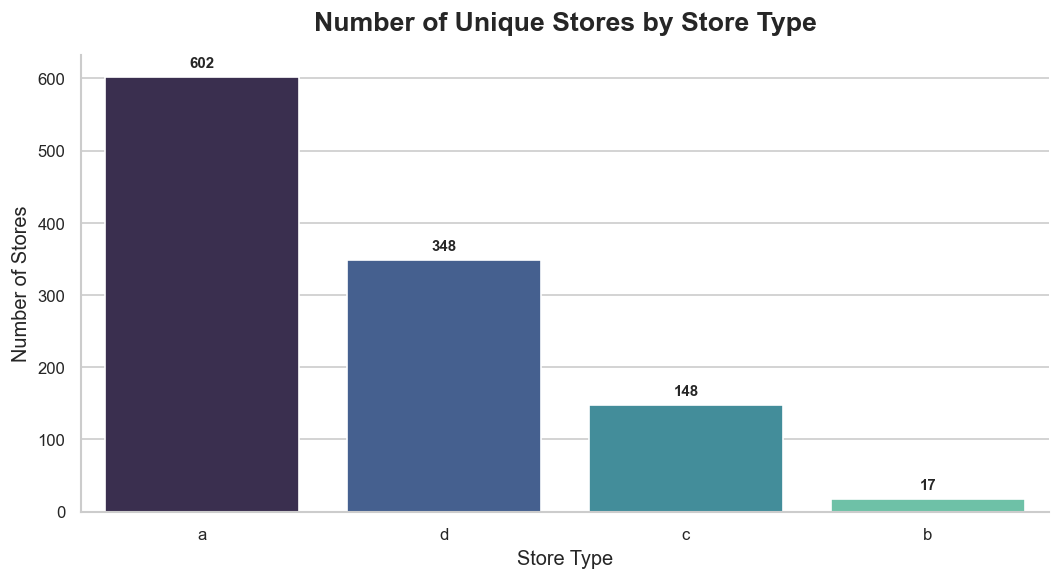

In [24]:
store_type_count = (
    train_df[["Store", "StoreType"]]
    .drop_duplicates()
    ["StoreType"]
    .value_counts()
    .reset_index()
)

store_type_count.columns = ["StoreType", "Store_Count"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=store_type_count,
    x="StoreType",
    y="Store_Count",
    hue="StoreType",
    palette="mako",
    legend=False
)

add_bar_labels(ax)

plt.title("Number of Unique Stores by Store Type", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Number of Stores")

plt.tight_layout()
plt.show()

### Insight
+ This plot provides a more accurate comparison of the number of individual stores in each category.
+ StoreType a have 602 number of stores, which is highest among all StoreType, whereas StoreType have noly 17 number of stores. Differences in store counts indicate that the Rossmann network has an unequal distribution of store types.
+ Store types with fewer stores may still generate high average sales, so store count alone should not be used to evaluate business performance.

## Assortment Distributions

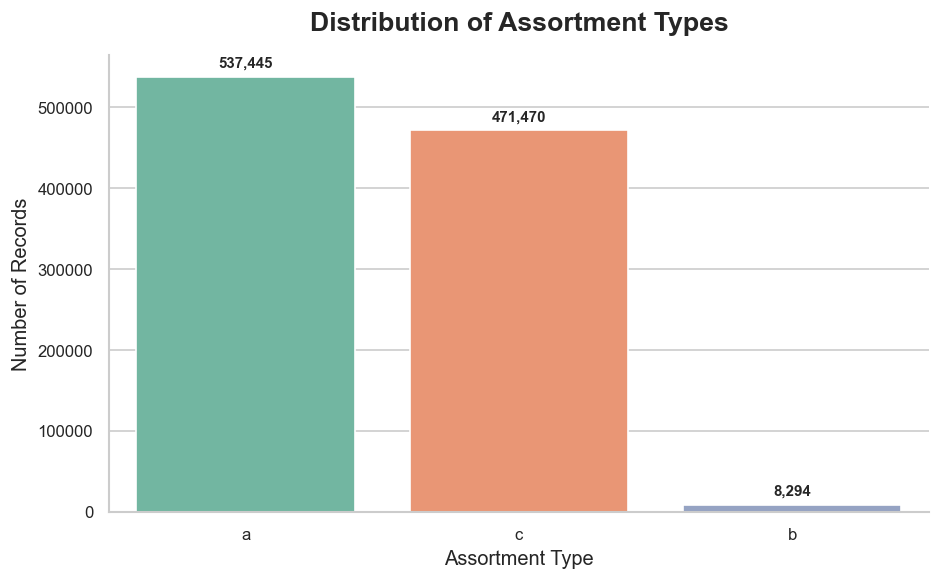

In [25]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train_df,
    x="Assortment",
    hue="Assortment",
    palette="Set2",
    legend=False
)

add_bar_labels(ax)

plt.title("Distribution of Assortment Types", pad=15)
plt.xlabel("Assortment Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()
logger.info("Assortment distribution analysis completed")


### Insight
+ The dataset contains three assortment categories: a, b, and c. AssortmentType a have 537,445 number of records, followed by c which have 471,470 number of records.
+ AssortmentType b have 8,294 number of records which are much less than AssortmentType a and c.
+ The distribution shows that the assortment categories are not equally represented.
+ This indicates that stores differ in the range and variety of products they offer.
+ Comparing assortment types with average sales and customer counts can help identify whether product variety is associated with store performance.

## Promotion Distribution

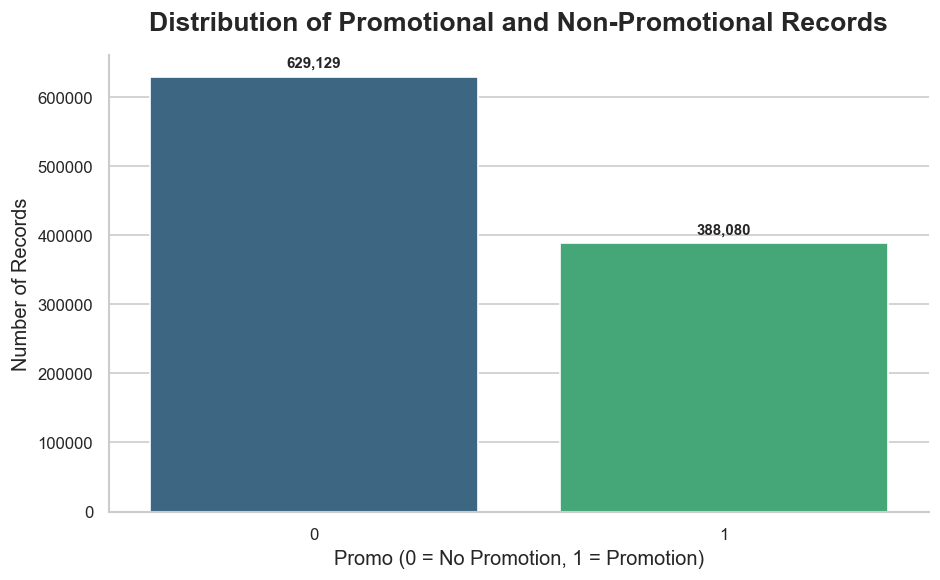

In [26]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train_df,
    x="Promo",
    hue="Promo",
    palette="viridis",
    legend=False
)

add_bar_labels(ax)

plt.title("Distribution of Promotional and Non-Promotional Records", pad=15)
plt.xlabel("Promo (0 = No Promotion, 1 = Promotion)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Insight
+ The dataset contains both promotional and non-promotional store-day records.
+ Non-promotional records (629,129) are more frequent than promotional records (388,080), indicating that promotions are not active every day.
+ The presence of both categories provides an opportunity to compare sales and customer activity under different promotional conditions.
+ The impact of promotions should be evaluated using average sales and average customers rather than record counts alone.

## Sales and Customers Analysis

### Relationships between Customers and Sales

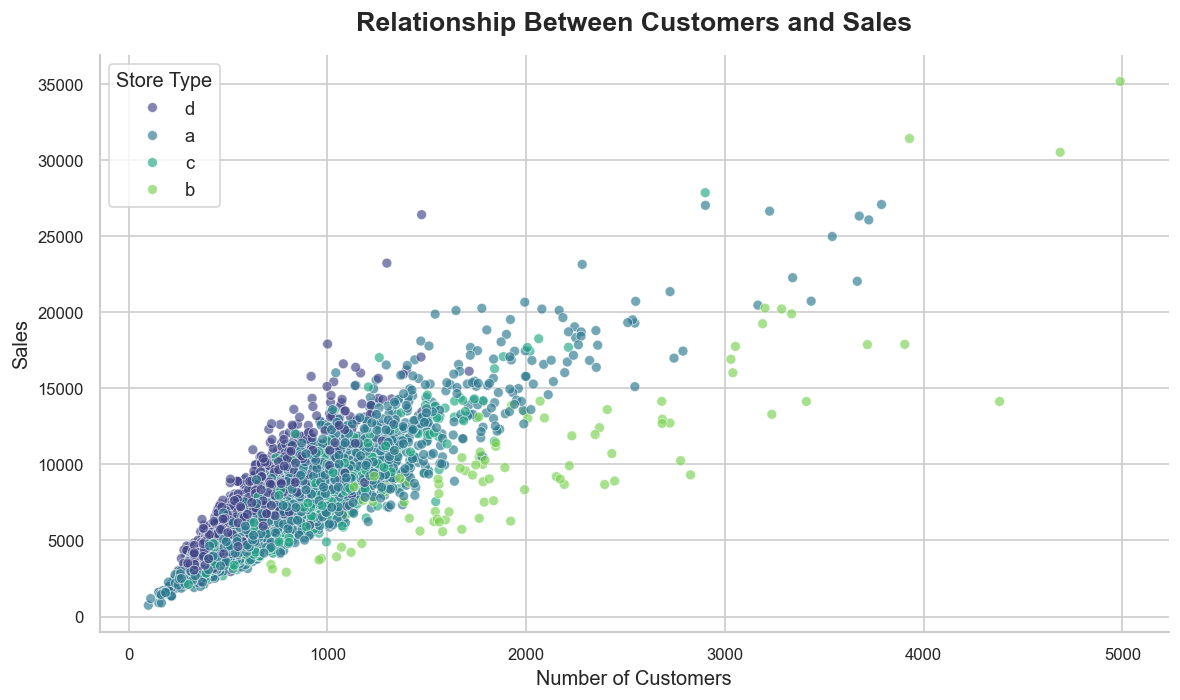

In [27]:
sample_data = open_train.sample(
    n=min(5000, len(open_train)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_data,
    x="Customers",
    y="Sales",
    hue="StoreType",
    palette="viridis",
    alpha=0.65,
    s=35
)

plt.title("Relationship Between Customers and Sales", pad=15)
plt.xlabel("Number of Customers")
plt.ylabel("Sales")
plt.legend(title="Store Type")

plt.tight_layout()
plt.show()

### Insight
+ The scatterplot shows a clear positive relationship between customer footfall and sales.
+ Store-day observations with higher customer counts generally tend to generate higher sales. This suggests that customer traffic is an important factor influencing store revenue.
+ However, the spread of points indicates that sales can also vary between stores with similar customer counts, potentially due to differences in purchasing behaviour and average transaction value.

### Correlation between Customers and Sales

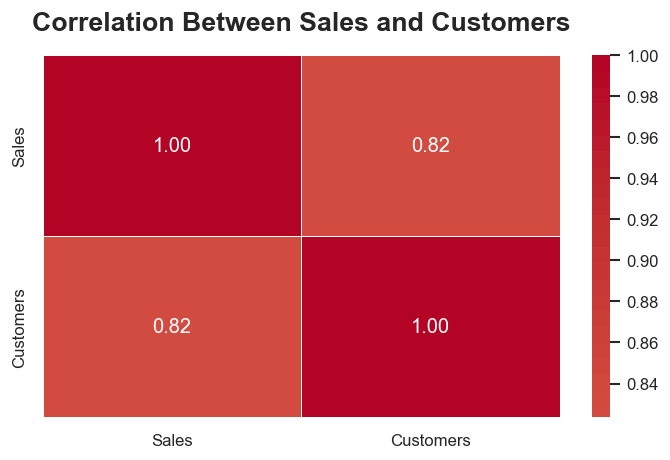

In [28]:
sales_customer_corr = open_train[
    ["Sales", "Customers"]
].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    sales_customer_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Sales and Customers", pad=15)

plt.tight_layout()
plt.show()

### Insight
+ There is a strong positive correlation of 0.82 between the number of customers and sales.
+ This indicates that an increase in customer footfall is generally associated with an increase in sales.
+ Customer count is therefore a useful variable for explaining historical sales patterns.
+ However, because customer counts are not provided in the test dataset, this feature cannot be directly used for final test predictions unless it is separately estimated or made available.

### Average Sales per Customer

In [29]:
open_train["Sales_Per_Customer"] = (
    open_train["Sales"] / open_train["Customers"].replace(0, np.nan)
)

print(
    "Average Sales per Customer:",
    open_train["Sales_Per_Customer"].mean()
)

Average Sales per Customer: 9.493619003355343


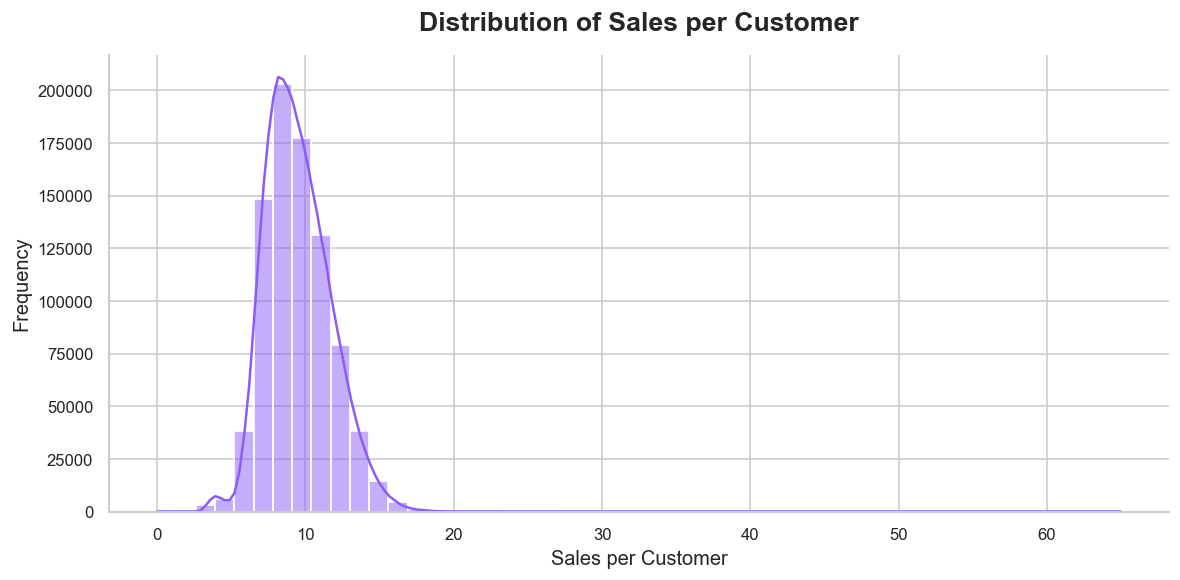

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=open_train,
    x="Sales_Per_Customer",
    bins=50,
    kde=True,
    color="#8B5CF6"
)

plt.title("Distribution of Sales per Customer", pad=15)
plt.xlabel("Sales per Customer")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
logger.info("Sales and customer distribution analysis completed")

### Insight
+ The average sales per customer is approximately 9.49, indicating the average sales value generated per customer across open-store observations.
+ The distribution helps understand differences in customer spending behaviour. Higher values indicate observations where customers generated more sales on average, while lower values indicate comparatively smaller spending.
+ This metric can help distinguish between stores that generate sales through higher customer footfall and those that generate sales through higher spending per customer.

## Time Based Analysis

In [31]:
train_df["Year"] = train_df["Date"].dt.year
train_df["Month"] = train_df["Date"].dt.month
train_df["Day"] = train_df["Date"].dt.day
train_df["Week"] = train_df["Date"].dt.isocalendar().week.astype(int)

train_df["DayOfWeek"] = train_df["DayOfWeek"].astype(int)

train_df["DayName"] = train_df["Date"].dt.day_name()

train_df["IsWeekend"] = (
    train_df["Date"].dt.dayofweek >= 5
).astype(int)

In [32]:
test_df["Year"] = test_df["Date"].dt.year
test_df["Month"] = test_df["Date"].dt.month
test_df["Day"] = test_df["Date"].dt.day
test_df["Week"] = test_df["Date"].dt.isocalendar().week.astype(int)

test_df["DayOfWeek"] = test_df["DayOfWeek"].astype(int)

test_df["DayName"] = test_df["Date"].dt.day_name()

test_df["IsWeekend"] = (
    test_df["Date"].dt.dayofweek >= 5
).astype(int)

In [33]:
open_train = train_df[train_df["Open"] == 1].copy()

### Yearly Sales Trend

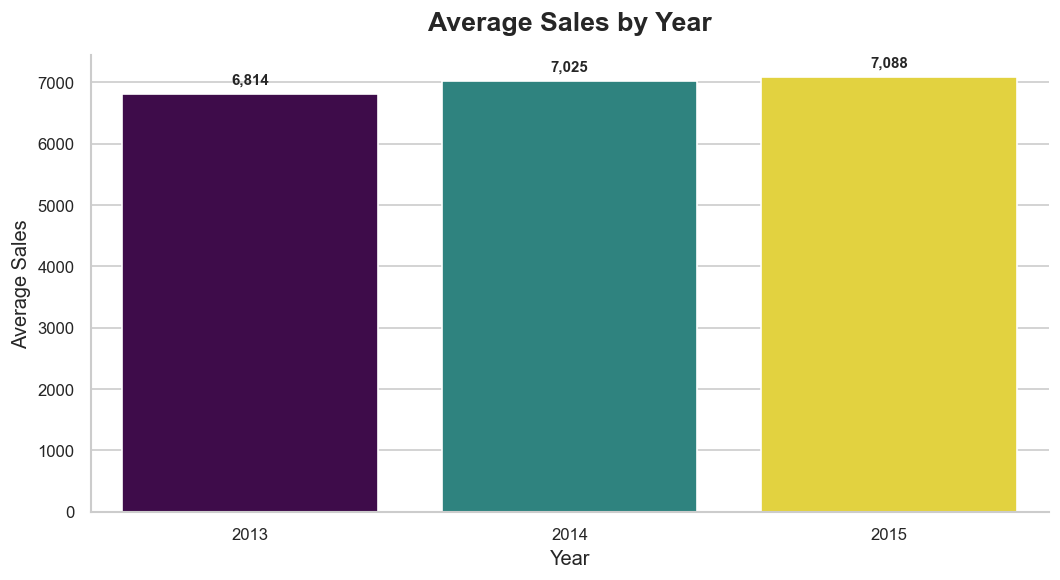

In [34]:
yearly_sales = (
    open_train.groupby("Year")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=yearly_sales,
    x="Year",
    y="Sales",
    hue="Year",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by Year", pad=15)
plt.xlabel("Year")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ The yearly comparison helps identify changes in average daily sales across the available years.
+ Average sales value increased slightly from 6,814 to 7,088 from year 2013 to 2015.
+ Differences between years may indicate changes in customer demand, business performance, and promotional activity.
+ The 2015 data covers only January to July, whereas 2013 and 2014 cover complete calendar years. Therefore, yearly average sales can be compared, but the results should be interpreted with the difference in time coverage in mind.

### Monthly Sales Trend

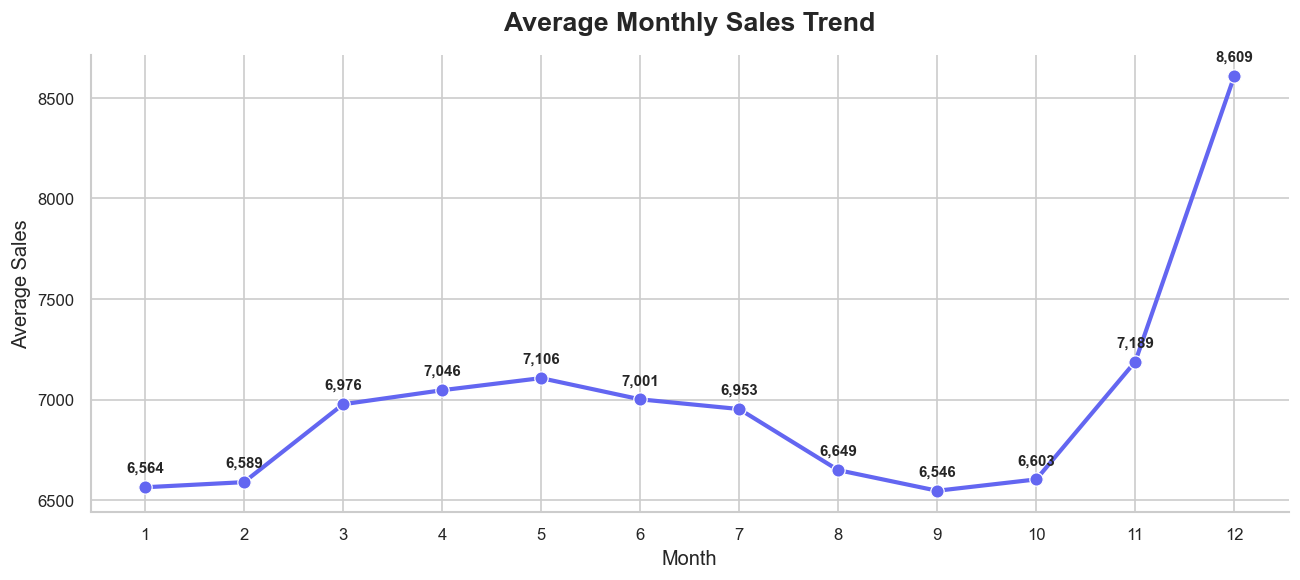

In [35]:
monthly_sales = (
    open_train.groupby("Month")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#6366F1"
)

for x, y in zip(monthly_sales["Month"], monthly_sales["Sales"]):
    plt.annotate(
        f"{y:,.0f}",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Average Monthly Sales Trend", pad=15)
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

### Insight
+ Monthly average sales help identify seasonal patterns in customer demand.
+ Variations across months suggest that sales performance is influenced by the time of year.
+ Months showing higher average sales may be associated with seasonal demand, holidays, or promotional activity.
+ Monthly patterns can be useful for identifying seasonality when developing a sales forecasting model.

### Day-of-Week Sales Analysis

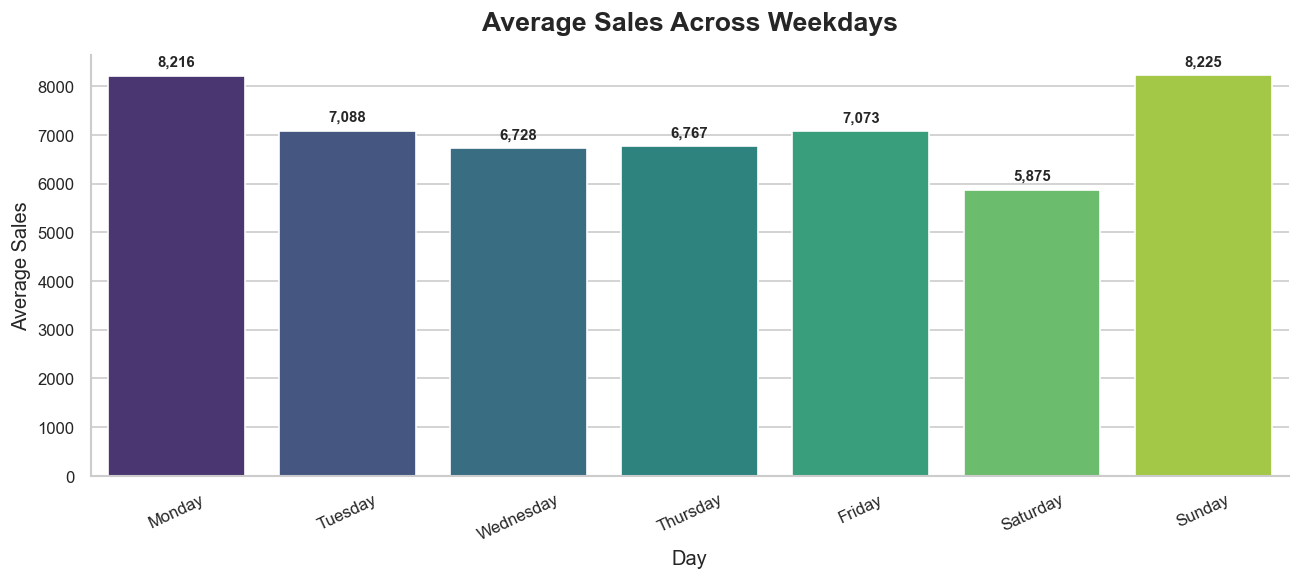

In [36]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

dayname_sales = (
    open_train.groupby("DayName")["Sales"]
    .mean()
    .reindex(day_order)
    .reset_index()
)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=dayname_sales,
    x="DayName",
    y="Sales",
    hue="DayName",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales Across Weekdays", pad=15)
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

### Insight
+ Average sales vary across the days of the week, indicating that customer purchasing behaviour is not consistent throughout the week.
+ Monday has average sales of approximately 8,216, while Sunday has approximately 8,225 in the summary table.
+ Tuesday to Saturday show comparatively different average sales levels.
+ Sunday requires special attention because only a relatively small number of stores are open on that day. Its average is therefore based on fewer observations and should not be interpreted as evidence that Sunday is generally the strongest sales day.

### Weekend vs Weekday Sales

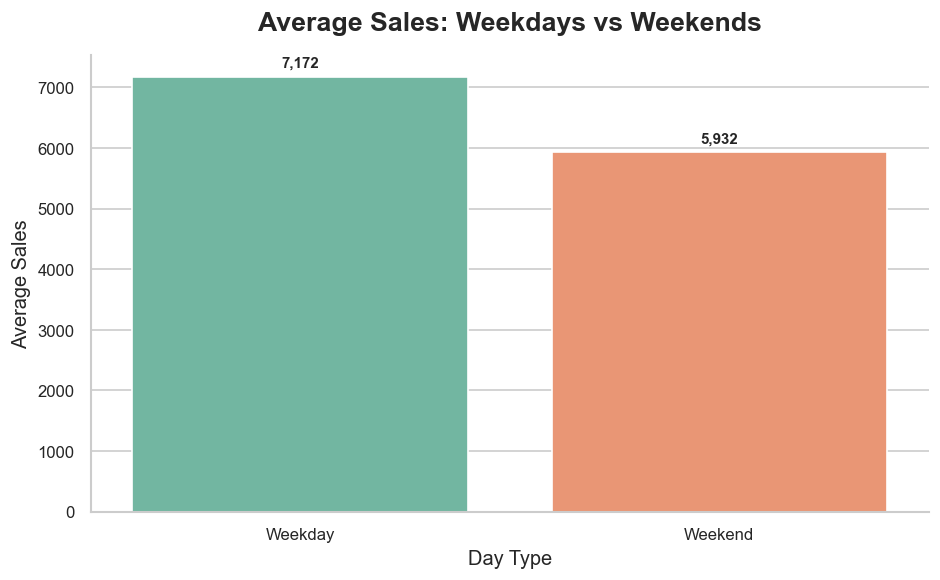

In [37]:
weekend_sales = open_train.copy()

weekend_sales["Day_Type"] = np.where(
    weekend_sales["IsWeekend"] == 1,
    "Weekend",
    "Weekday"
)

weekend_avg = (
    weekend_sales.groupby("Day_Type")["Sales"]
    .mean()
    .reindex(["Weekday", "Weekend"])
    .reset_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=weekend_avg,
    x="Day_Type",
    y="Sales",
    hue="Day_Type",
    palette="Set2",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales: Weekdays vs Weekends", pad=15)
plt.xlabel("Day Type")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ The comparison highlights differences in sales performance between weekdays and weekends. Weekend sales are influenced by the fact that fewer stores may operate on Sundays.
+ As a result, the weekend average (5,932) combines Saturday and Sunday observations and may be affected by the smaller number of Sunday records.
+ Day-level analysis provides additional detail that can be hidden when weekdays and weekends are grouped together.

### Monthly Sales Heatmap

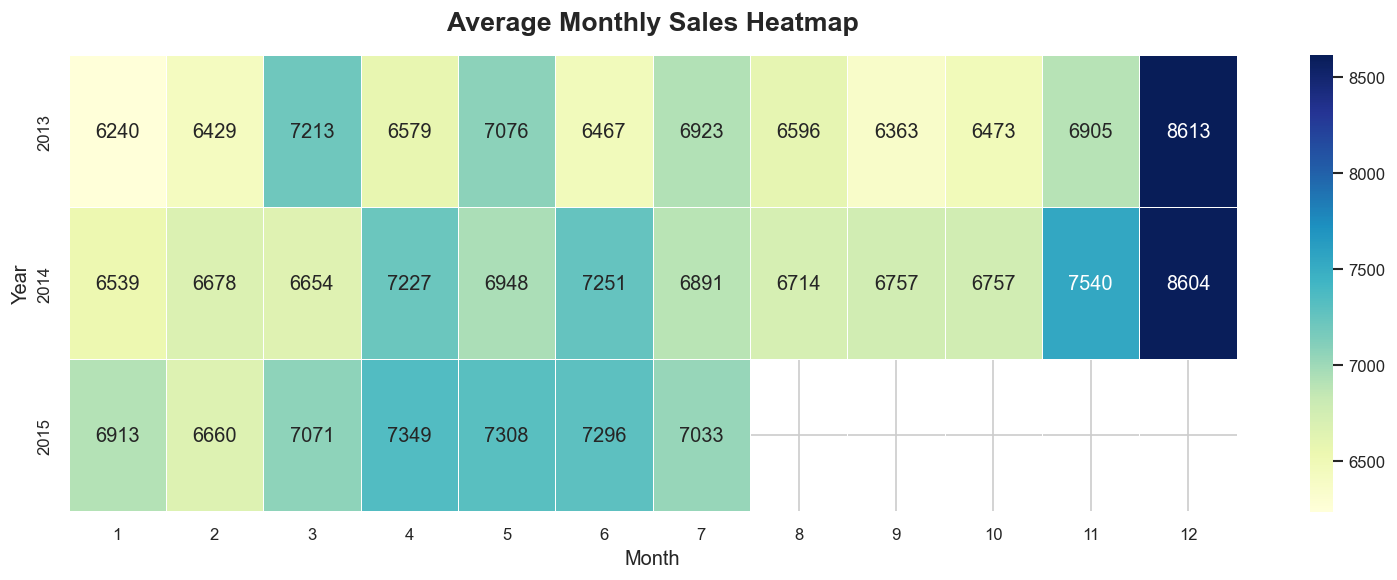

In [38]:
monthly_heatmap = (
    open_train.pivot_table(
        index="Year",
        columns="Month",
        values="Sales",
        aggfunc="mean"
    )
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    monthly_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Monthly Sales Heatmap", pad=15)
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()
logger.info("Time based analysis completed")

### Insight
+ The heatmap provides a combined view of monthly and yearly sales patterns.
+ Differences in colour intensity indicate variations in average sales across different months and years.
+ December month shows maximum sales among all month in year 2013 and 2014. 
+ It helps identify months with comparatively high or low sales and observe whether similar seasonal patterns occur across multiple years.
+ The 2015 row represents only January to July, so comparisons with complete years should be made carefully.

## Promotion Analysis

### Promo vs Average Sales

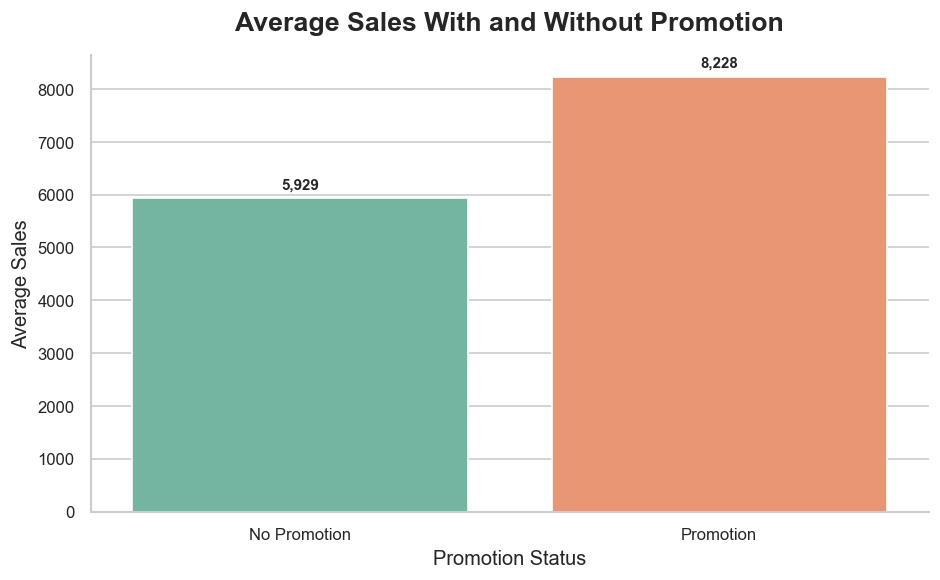

In [39]:
promo_sales = (
    open_train.groupby("Promo")["Sales"]
    .mean()
    .reset_index()
)

promo_sales["Promo_Label"] = promo_sales["Promo"].map({
    0: "No Promotion",
    1: "Promotion"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=promo_sales,
    x="Promo_Label",
    y="Sales",
    hue="Promo_Label",
    palette="Set2",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales With and Without Promotion", pad=15)
plt.xlabel("Promotion Status")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
- No promotion: average sales of 5,929
- Promotion: average sales of 8,228
- Average sales are higher on promotional days than on non-promotional days.
- Promotional days generate approximately 38.8% higher average sales than non-promotional days.
- This suggests that promotions are associated with increased sales activity.
- Promotions may encourage customers to purchase more products or visit stores more frequently.

### Promo vs Average Customers

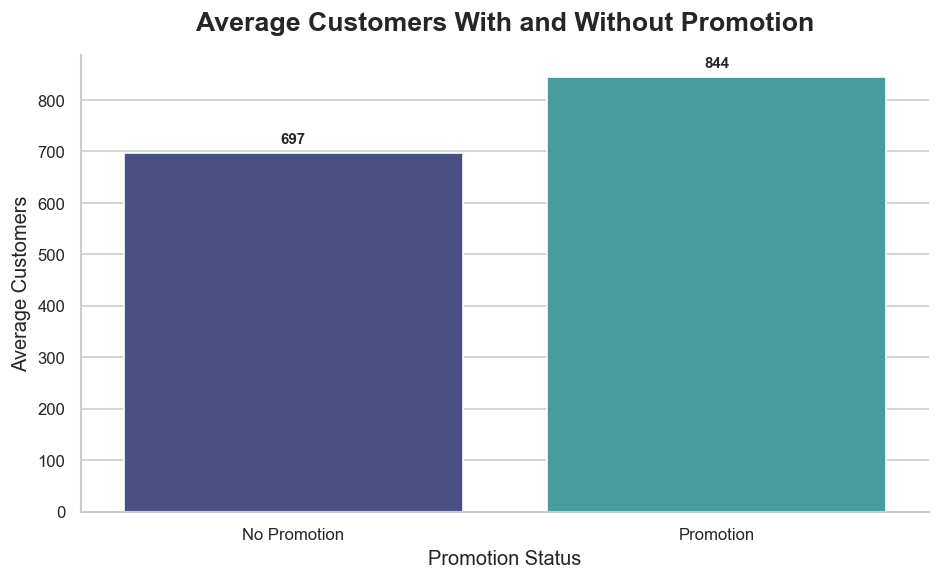

In [40]:
promo_customers = (
    open_train.groupby("Promo")["Customers"]
    .mean()
    .reset_index()
)

promo_customers["Promo_Label"] = promo_customers["Promo"].map({
    0: "No Promotion",
    1: "Promotion"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=promo_customers,
    x="Promo_Label",
    y="Customers",
    hue="Promo_Label",
    palette="mako",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Customers With and Without Promotion", pad=15)
plt.xlabel("Promotion Status")
plt.ylabel("Average Customers")

plt.tight_layout()
plt.show()

### Insight
- No promotion: approximately 697 customers
- Promotion: approximately 844 customers
- Promotional days have higher average customer footfall than non-promotional days.
- This indicates that promotions are associated with increased store visits.
- The increase in customer numbers may contribute to the higher average sales observed during promotional periods.

### Promotion Impact across Store Types

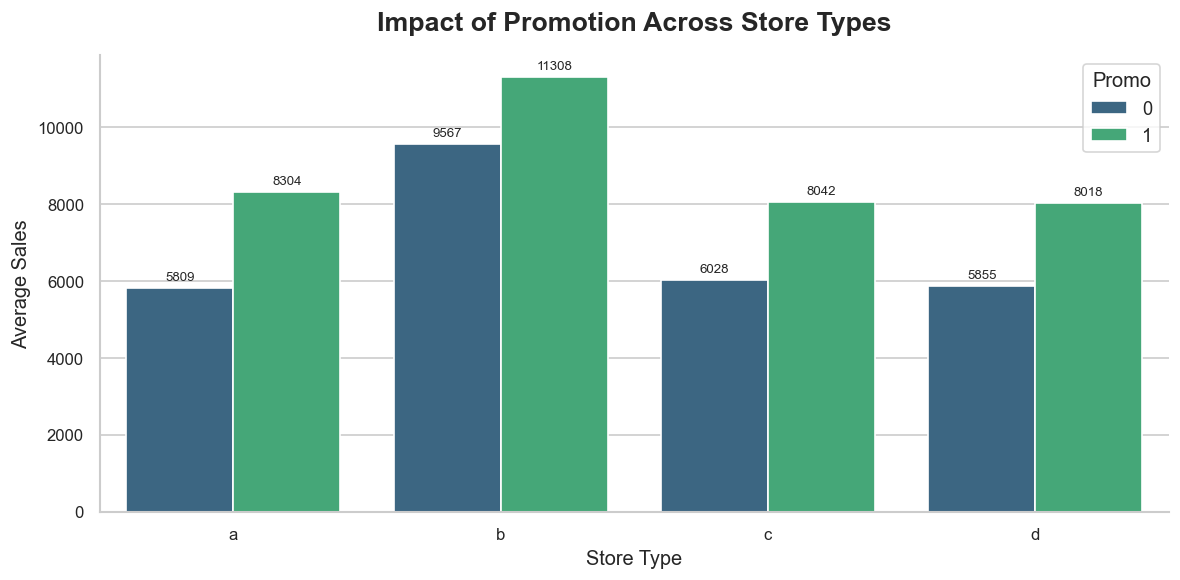

In [41]:
promo_store_sales = (
    open_train.groupby(["StoreType", "Promo"])["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=promo_store_sales,
    x="StoreType",
    y="Sales",
    hue="Promo",
    palette="viridis"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=8
    )

plt.title("Impact of Promotion Across Store Types", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.legend(title="Promo")

plt.tight_layout()
plt.show()
logger.info("Promotion analysis completed")

### Insight
+ The plot compares promotional and non-promotional sales across different store types. It helps identify whether promotions are associated with higher sales across all store categories or whether the difference varies by store type.
+ Differences between store types suggest that promotional activity may not have an identical impact across the entire store network.
+ This comparison can help identify store categories where promotional strategies are particularly relevant.

## Holiday Analysis

### StateHoliday Distribution

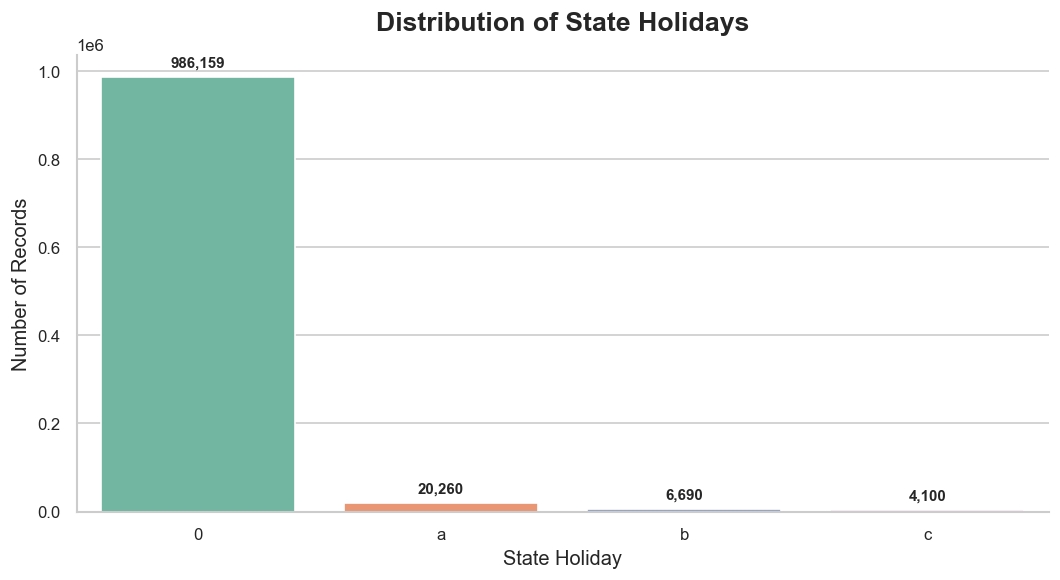

In [42]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=train_df,
    x="StateHoliday",
    hue="StateHoliday",
    palette="Set2",
    legend=False
)

add_bar_labels(ax)

plt.title("Distribution of State Holidays", pad=15)
plt.xlabel("State Holiday")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Insight
+ The majority of records (986,159) belong to regular non-state-holiday days.
+ State holiday observations are comparatively less frequent. Public holidays (a) have 20,260 records, easter holiday (b) have only 6,690 record and christmas (c) have least number of records (4,100).
+ This indicates that the dataset contains more regular trading days than state holiday periods.
+ The different holiday categories provide an opportunity to examine how special holidays influence store operations and sales.

### StateHoliday vs Average Sales

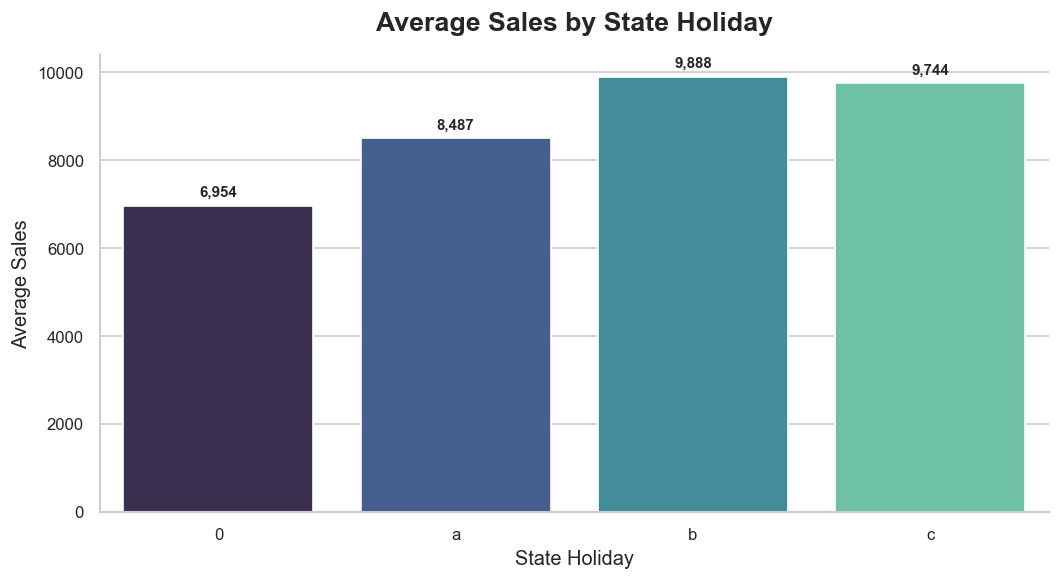

In [43]:
state_sales = (
    open_train.groupby("StateHoliday")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=state_sales,
    x="StateHoliday",
    y="Sales",
    hue="StateHoliday",
    palette="mako",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by State Holiday", pad=15)
plt.xlabel("State Holiday")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ Average sales vary across the state holiday categories.
+ State holidays may affect customer shopping behaviour and store operations.
+ The comparison should be interpreted carefully because some holiday categories (like 0) contain fewer observations than regular days.
+ The sales pattern across holiday categories can help the forecasting model capture special-day effects.

### SchoolHoliday vs Average Sales

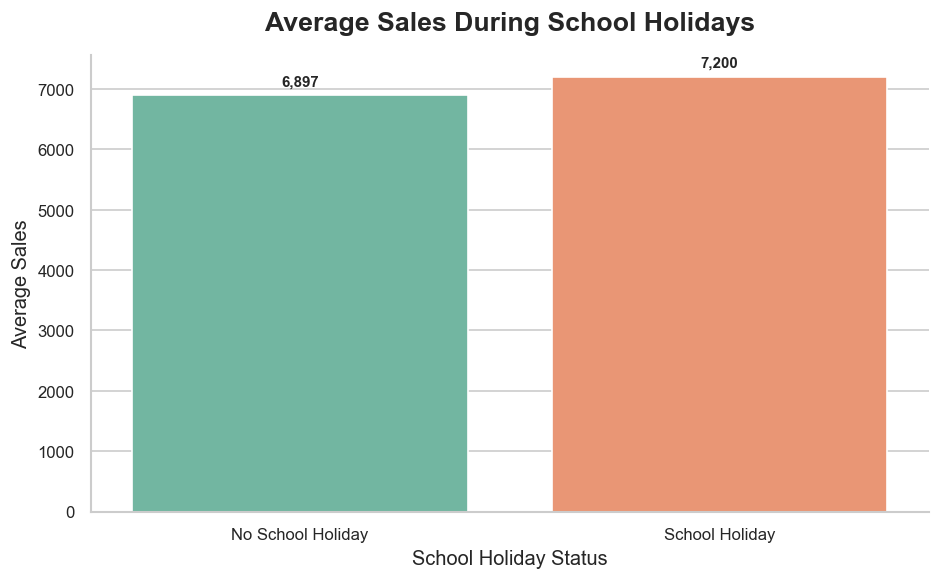

In [44]:
school_sales = (
    open_train.groupby("SchoolHoliday")["Sales"]
    .mean()
    .reset_index()
)

school_sales["Holiday_Label"] = school_sales["SchoolHoliday"].map({
    0: "No School Holiday",
    1: "School Holiday"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=school_sales,
    x="Holiday_Label",
    y="Sales",
    hue="Holiday_Label",
    palette="Set2",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales During School Holidays", pad=15)
plt.xlabel("School Holiday Status")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ The plot compares average sales on school holidays and non-school holidays.
+ Average sales for SchoolHoliday is 7,200, while for No SchoolHoliday average sale is 6,897. Differences between the two categories suggest that school holiday periods may influence shopping activity.
+ The impact may depend on customer routines, family shopping behaviour, and store location.
+ School holidays should be considered as a potentially useful feature for sales forecasting.

### SchoolHoliday vs Average Customers

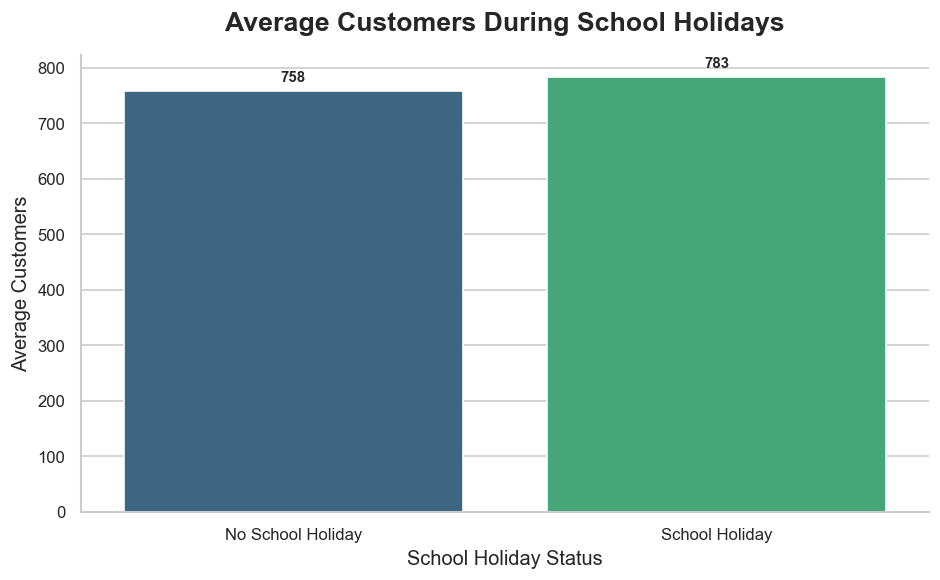

In [45]:
school_customers = (
    open_train.groupby("SchoolHoliday")["Customers"]
    .mean()
    .reset_index()
)

school_customers["Holiday_Label"] = school_customers["SchoolHoliday"].map({
    0: "No School Holiday",
    1: "School Holiday"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=school_customers,
    x="Holiday_Label",
    y="Customers",
    hue="Holiday_Label",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Customers During School Holidays", pad=15)
plt.xlabel("School Holiday Status")
plt.ylabel("Average Customers")

plt.tight_layout()
plt.show()
logger.info("Holiday analysis completed")

### Insight
+ Customer footfall differs between school holiday and non-school holiday periods.
+ Average customers on school holiday are 783, whereas for no school holiday average customers are 758.
+ This indicates that school holidays may influence the number of people visiting stores.
+ Comparing customer counts with sales helps determine whether changes in sales are associated with changes in customer traffic.

## Store Type and Assortment Analysis

### Average Sales by StoreType

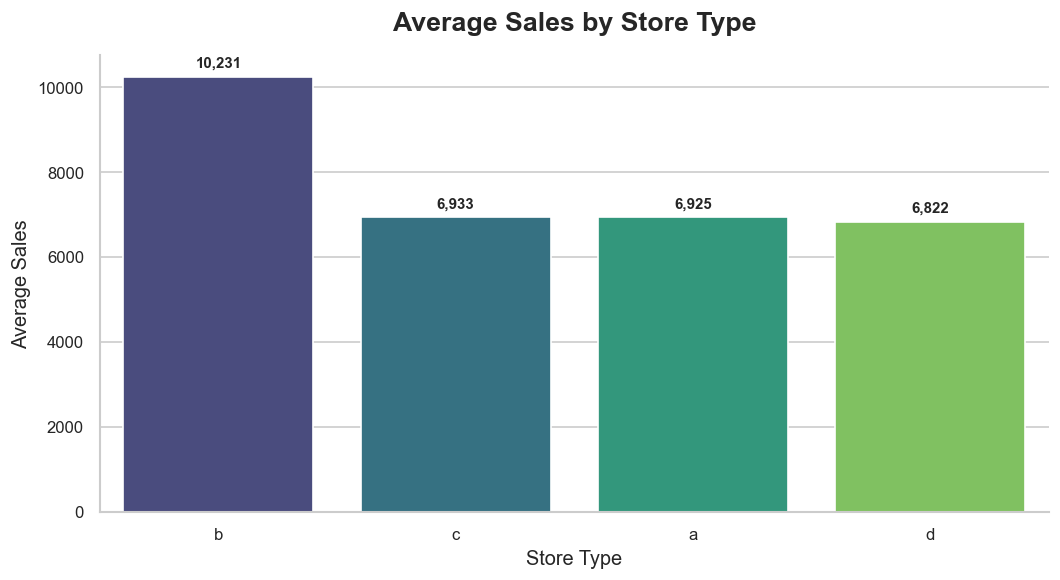

In [46]:
storetype_sales = (
    open_train.groupby("StoreType")["Sales"]
    .mean()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=storetype_sales,
    x="StoreType",
    y="Sales",
    hue="StoreType",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by Store Type", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ Store Type b records the highest average sales, approximately 10,231 per open-store observation.
+ Store Types a, c, and d have relatively similar average sales.
+ This indicates that sales performance differs across store categories.
+ Store Type b may have a different business format or customer profile that contributes to its higher average sales.

### Average Customers by StoreType

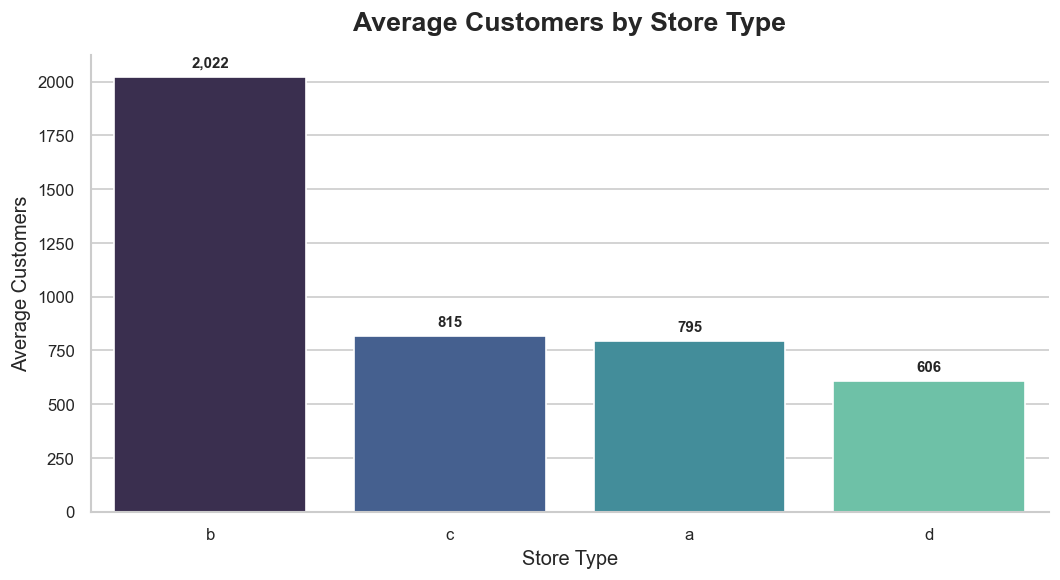

In [47]:
storetype_customers = (
    open_train.groupby("StoreType")["Customers"]
    .mean()
    .reset_index()
    .sort_values("Customers", ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=storetype_customers,
    x="StoreType",
    y="Customers",
    hue="StoreType",
    palette="mako",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Customers by Store Type", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Average Customers")

plt.tight_layout()
plt.show()

### Insight 
+ Store Type b has the highest average customer footfall, with approximately 2,022 customers.
+ Store Type d has the lowest average customer footfall among the four categories.
+ Store Types a and c have relatively similar average customer counts.
+ The higher average sales of Store Type b are accompanied by substantially higher customer footfall.

### Sales Distribution by SalesType

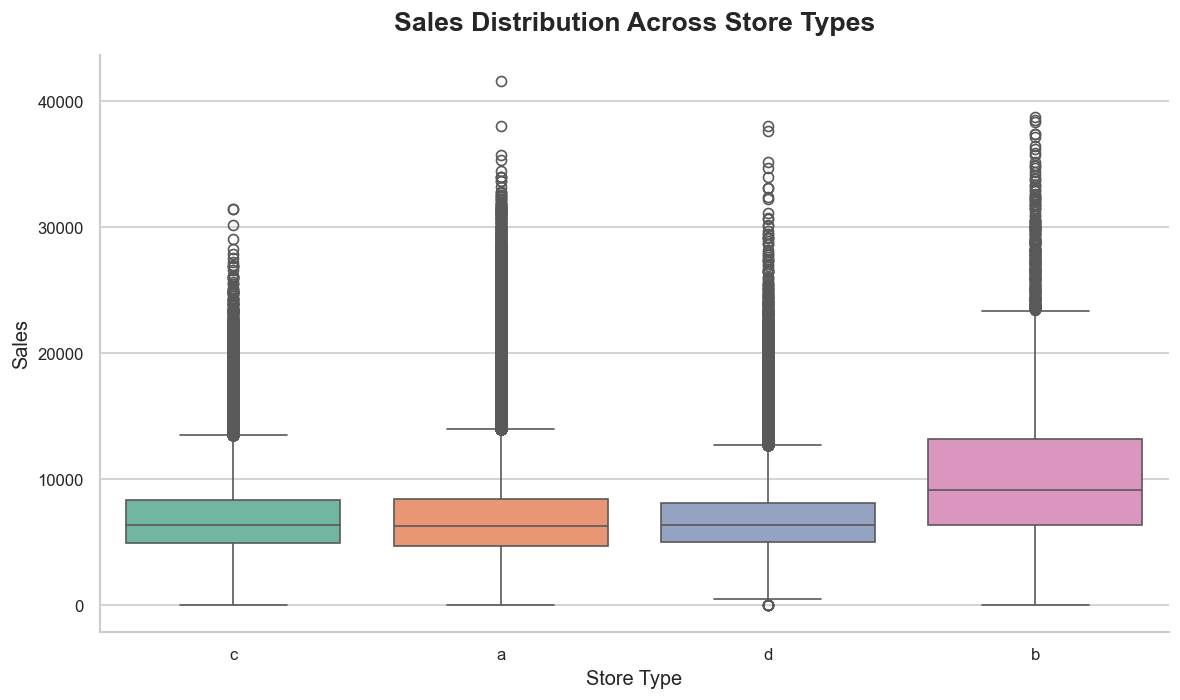

In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=open_train,
    x="StoreType",
    y="Sales",
    hue="StoreType",
    palette="Set2",
    legend=False
)

plt.title("Sales Distribution Across Store Types", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

### Insight
+ The boxplot shows differences in the median sales, spread, and outliers across store types.
+ Store Type b has a higher sales level overall, consistent with its higher average sales.
+ The presence of outliers indicates that some store-day observations generate exceptionally high sales compared with the typical observations in their category.
+ The spread of sales values suggests that daily performance varies even within the same store type.

### Average Sales by Assortment

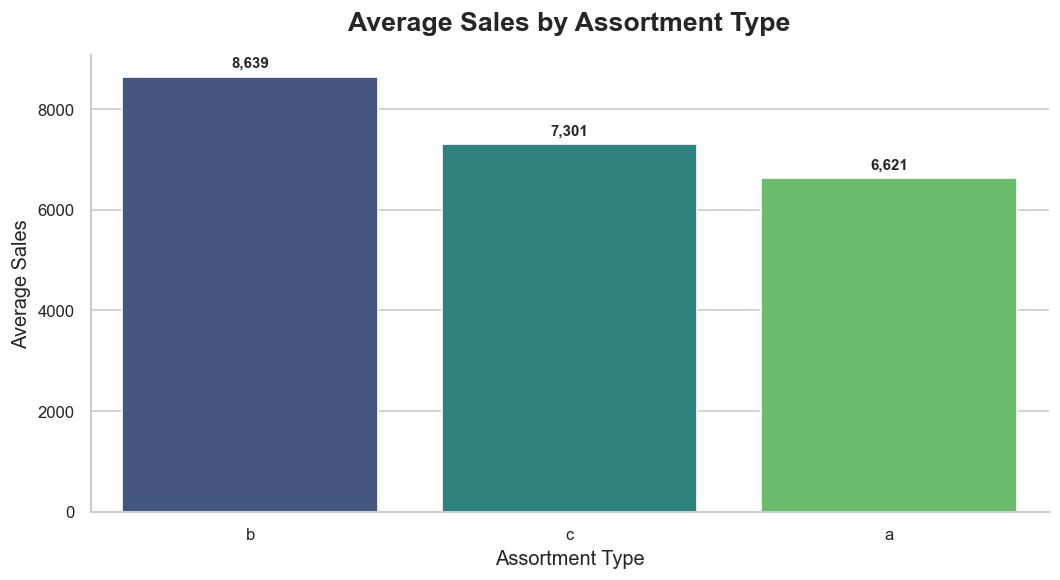

In [49]:
assortment_sales = (
    open_train.groupby("Assortment")["Sales"]
    .mean()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=assortment_sales,
    x="Assortment",
    y="Sales",
    hue="Assortment",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by Assortment Type", pad=15)
plt.xlabel("Assortment Type")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
+ Assortment b records the highest average sales of 8,639, followed by c and a.
+ Assortment a has the lowest average sales of 6,621 among the three categories.
+ This suggests that average sales performance differs across assortment categories.
+ However, assortment b may have fewer stores, so its higher average should be considered alongside its store count.

### StoreType vs Assortment

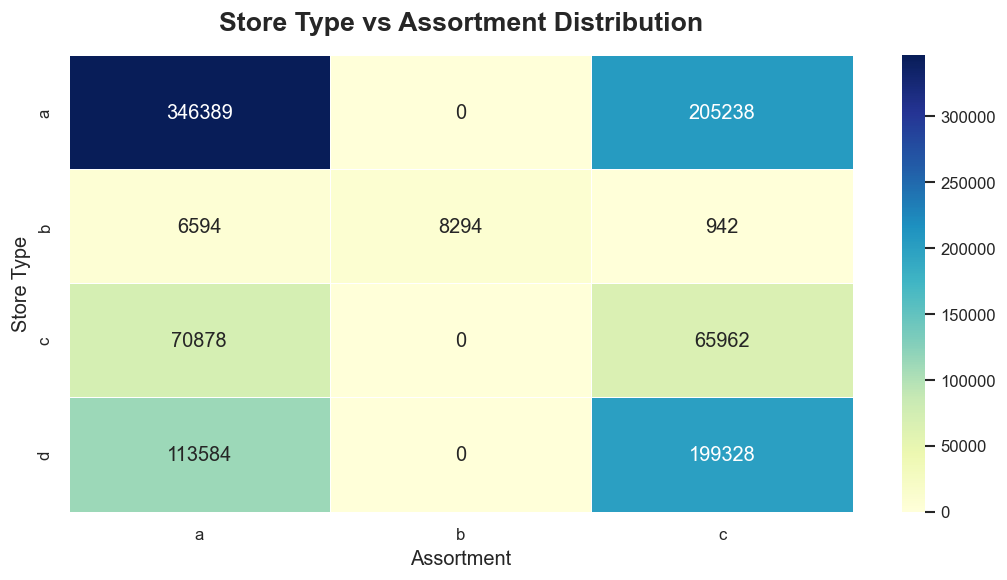

In [50]:
store_assortment = (
    train_df.groupby(["StoreType", "Assortment"])
    .size()
    .reset_index(name="Count")
)

store_assortment_pivot = store_assortment.pivot(
    index="StoreType",
    columns="Assortment",
    values="Count"
).fillna(0)

plt.figure(figsize=(9, 5))

sns.heatmap(
    store_assortment_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Store Type vs Assortment Distribution", pad=15)
plt.xlabel("Assortment")
plt.ylabel("Store Type")

plt.tight_layout()
plt.show()
logger.info("StoreType and Assortment analysis completed")

### Insight
+ The heatmap shows how assortment categories are distributed across different store types.
+ Some store type and assortment combinations are more common than others.
+ This indicates that product assortment is not distributed uniformly across the store network.
+ The relationship between store type and assortment may help explain differences in sales performance between store categories.

## Competition Analysis

### CompetitionDistance Distribution

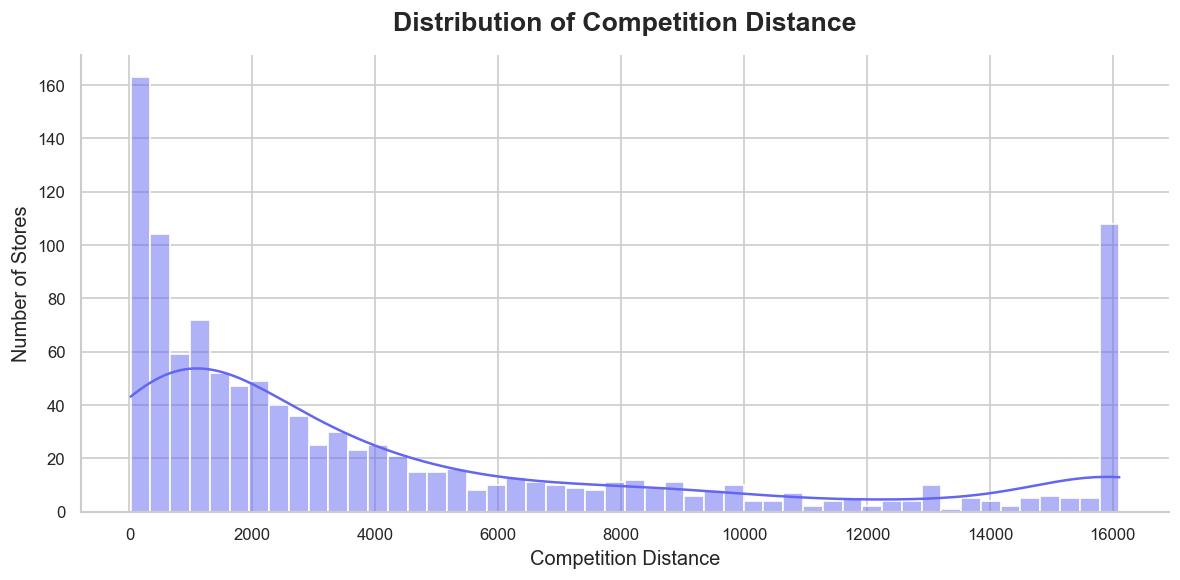

In [51]:
store_data = (
    train_df[
        ["Store", "CompetitionDistance"]
    ]
    .drop_duplicates(subset="Store")
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=store_data,
    x="CompetitionDistance",
    bins=50,
    kde=True,
    color="#6366F1"
)

plt.title("Distribution of Competition Distance", pad=15)
plt.xlabel("Competition Distance")
plt.ylabel("Number of Stores")

plt.tight_layout()
plt.show()

### Insight
+ Competition distance varies considerably across stores.
+ The distribution indicates that some stores have competitors located nearby, while others have competitors at much greater distances.
+ The spread suggests that stores operate under different competitive conditions.
+ Competition distance may be useful for understanding differences in store performance and forecasting sales.

### CompetitionDistance vs Average Sales

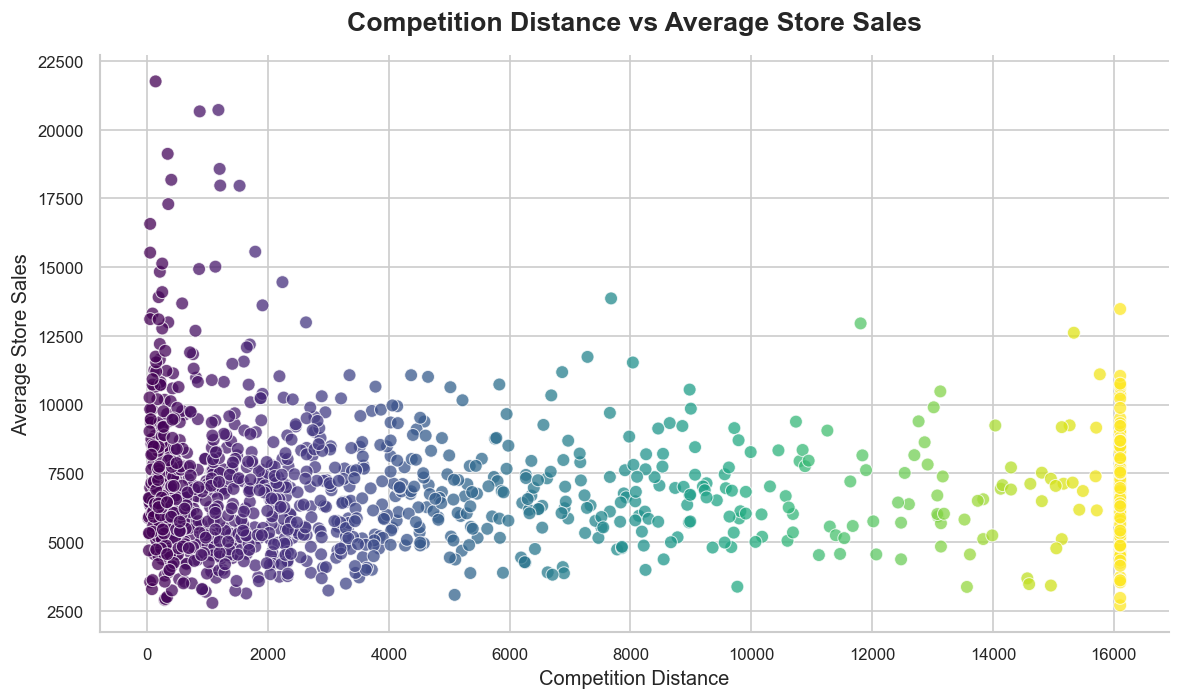

In [52]:
competition_sales = (
    open_train.groupby("Store")
    .agg(
        CompetitionDistance=("CompetitionDistance", "first"),
        AverageSales=("Sales", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=competition_sales,
    x="CompetitionDistance",
    y="AverageSales",
    hue="CompetitionDistance",
    palette="viridis",
    alpha=0.75,
    s=60,
    legend=False
)

plt.title("Competition Distance vs Average Store Sales", pad=15)
plt.xlabel("Competition Distance")
plt.ylabel("Average Store Sales")

plt.tight_layout()
plt.show()

### Insight
+ The scatterplot compares the distance to the nearest competitor with each store's average sales.
+ Sales values vary across different competition distances, suggesting that competition distance alone does not fully explain store performance.
+ Stores with nearby competitors may still generate strong sales, while stores with more distant competitors may not necessarily have the highest sales.
+ Other factors, such as store type, location, customer footfall, and promotions, may also influence sales.

### CompetitionDistance Categories

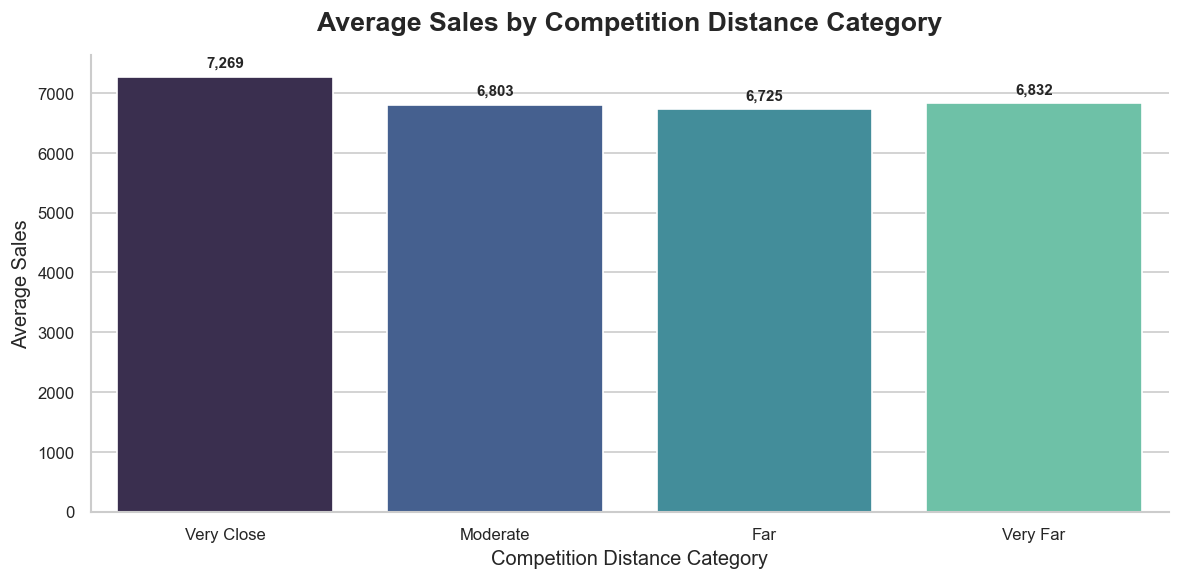

In [53]:
store_data["Competition_Category"] = pd.cut(
    store_data["CompetitionDistance"],
    bins=[-1, 1000, 5000, 10000, np.inf],
    labels=[
        "Very Close",
        "Moderate",
        "Far",
        "Very Far"
    ]
)

competition_category = (
    train_df[["Store", "CompetitionDistance"]]
    .drop_duplicates(subset="Store")
    .merge(
        store_data[["Store", "Competition_Category"]],
        on="Store",
        how="left"
    )
)

competition_category_sales = (
    open_train.groupby("Store")["Sales"]
    .mean()
    .reset_index(name="AverageSales")
    .merge(
        competition_category[["Store", "Competition_Category"]],
        on="Store",
        how="left"
    )
)

category_sales = (
    competition_category_sales
    .groupby("Competition_Category", observed=True)["AverageSales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=category_sales,
    x="Competition_Category",
    y="AverageSales",
    hue="Competition_Category",
    palette="mako",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by Competition Distance Category", pad=15)
plt.xlabel("Competition Distance Category")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()
logger.info("CompetitionDistance analysis completed")

### Insight
+ The plot compares average store sales across four competition-distance categories: Very Close, Moderate, Far, and Very Far.
+ Average store sales when competitor store is very close is 7,269, which is slightly higher than when competitor store distance is moderate or very far. Differences between categories may indicate whether the competitive environment is associated with store performance.
+ The relationship should not be interpreted as direct evidence that greater competition distance causes higher sales. Competition distance is one of several factors that may influence sales.

## Promo2 Analysis

### Promo2 Distribution

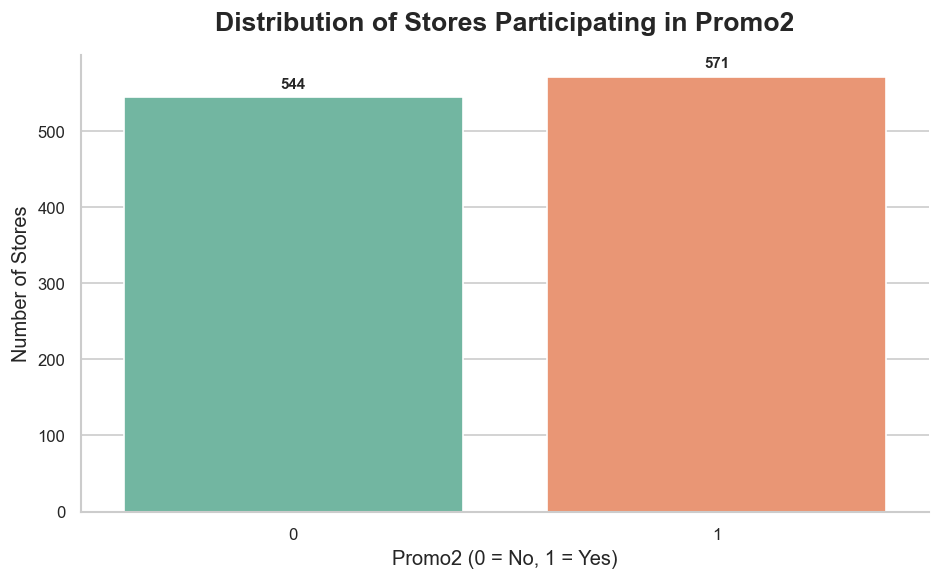

In [54]:
store_promo = (
    train_df[["Store", "Promo2"]]
    .drop_duplicates(subset="Store")
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=store_promo,
    x="Promo2",
    hue="Promo2",
    palette="Set2",
    legend=False
)

add_bar_labels(ax)

plt.title("Distribution of Stores Participating in Promo2", pad=15)
plt.xlabel("Promo2 (0 = No, 1 = Yes)")
plt.ylabel("Number of Stores")

plt.tight_layout()
plt.show()

### Insight
+ The number of stores participating (571) in Promo2 is slightly higher than the number not participating (544).
+ This indicates that Promo2 is used by a little over half of the stores.
+ The distribution provides a useful basis for comparing sales performance between participating and non-participating stores.

### Promo2 vs Average Sales

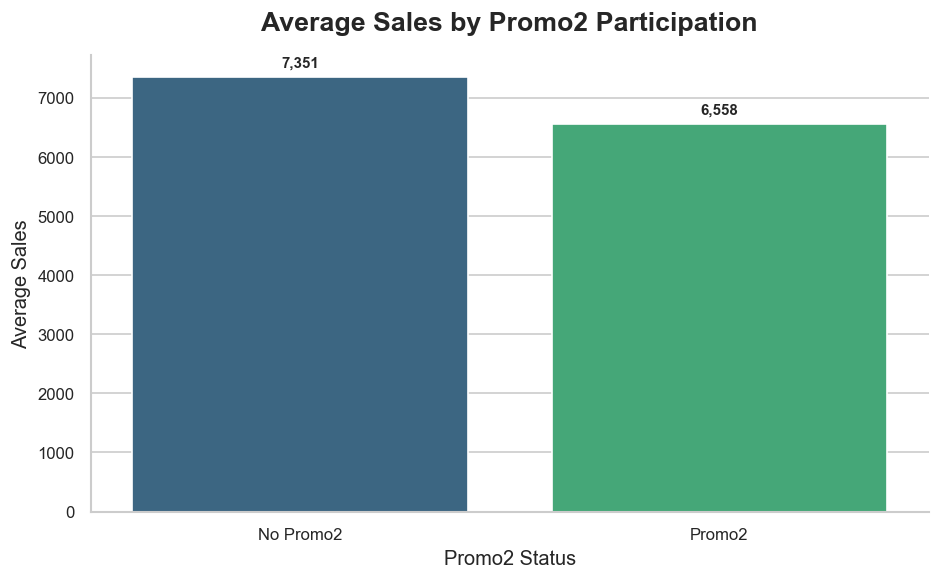

In [55]:
promo2_sales = (
    open_train.groupby("Promo2")["Sales"]
    .mean()
    .reset_index()
)

promo2_sales["Promo2_Label"] = promo2_sales["Promo2"].map({
    0: "No Promo2",
    1: "Promo2"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=promo2_sales,
    x="Promo2_Label",
    y="Sales",
    hue="Promo2_Label",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Average Sales by Promo2 Participation", pad=15)
plt.xlabel("Promo2 Status")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

### Insight
- The plot compares average sales between stores participating in Promo2 and stores not participating in the program.
- The average sales of stores not participating in Promo2 is 7,351, which is slightly higher than the average sales of 6,558 of the stores participating in Promo2.
- Differences in average sales may indicate an association between long-term promotional participation and store performance.
- However, stores participating in Promo2 may differ from other stores in terms of location, store type, or customer demand. Therefore, the difference in average sales should not be interpreted as the direct effect of Promo2 alone.

### PromoInterval Distribution

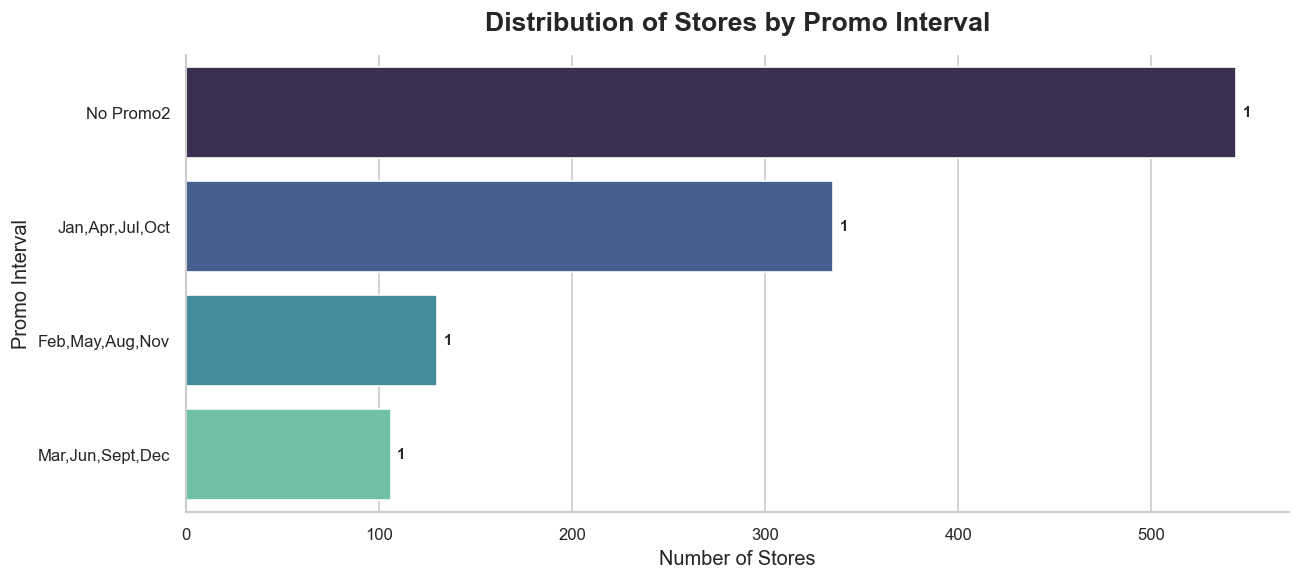

In [56]:
interval_data = (
    train_df[["Store", "PromoInterval"]]
    .drop_duplicates(subset="Store")
)

plt.figure(figsize=(11, 5))

ax = sns.countplot(
    data=interval_data,
    y="PromoInterval",
    order=interval_data["PromoInterval"].value_counts().index,
    hue="PromoInterval",
    palette="mako",
    legend=False
)

add_bar_labels(ax)

plt.title("Distribution of Stores by Promo Interval", pad=15)
plt.xlabel("Number of Stores")
plt.ylabel("Promo Interval")

plt.tight_layout()
plt.show()
logger.info("Promo2 analysis completed")

### Insight
+ The plot shows how stores are distributed across different promotional intervals.
+ The No Promo2 category represents stores that do not participate in the Promo2 program.
+ The remaining categories represent the months in which participating stores repeat their promotions.
+ This feature provides additional information about the timing of recurring promotional campaigns.

## Train and Test Dataset Comparison

### Compare Shape and Date Ranges

In [57]:
print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

print("Train Date Range:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTest Date Range:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Train Shape: (1017209, 26)
Test Shape: (41088, 25)
Train Date Range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Test Date Range:
2015-08-01 00:00:00 to 2015-09-17 00:00:00


### Insight
+ The training dataset contains historical sales information used for model development.
+ The test dataset covers a future period immediately following the training period.
+ The test dataset does not contain the Sales and Customers columns, as these are not provided for the prediction period.
+ The taining dataset contains 1,017,209 records and 26 columns, while test dataset contains 41,088 records and 25 columns. 
+ The training and testing datasets have different numbers of columns because the target and customer information are unavailable in the test data.
+ The continuous date ranges make the dataset suitable for a time-based forecasting approach.

### Compare Promo Distribution

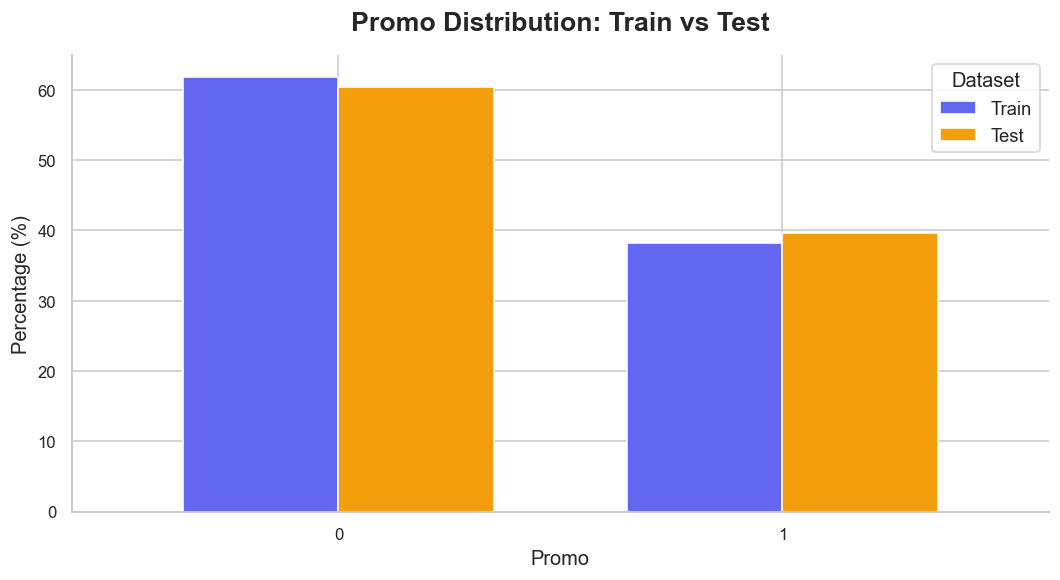

In [58]:
train_promo = train_df["Promo"].value_counts(normalize=True).sort_index()
test_promo = test_df["Promo"].value_counts(normalize=True).sort_index()

promo_comparison = pd.DataFrame({
    "Train": train_promo,
    "Test": test_promo
}).fillna(0) * 100

promo_comparison.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#6366F1", "#F59E0B"],
    width=0.7
)

plt.title("Promo Distribution: Train vs Test", pad=15)
plt.xlabel("Promo")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

### Insight
+ The plot compares the percentage of promotional and non-promotional records in the training and testing datasets.
+ Similar distributions indicate that promotional conditions are represented relatively consistently across both datasets. Any differences may affect model predictions because promotional activity is an important factor associated with sales.
+ Comparing feature distributions helps identify potential differences between the historical and prediction periods.

### Compare StoreType Distribution

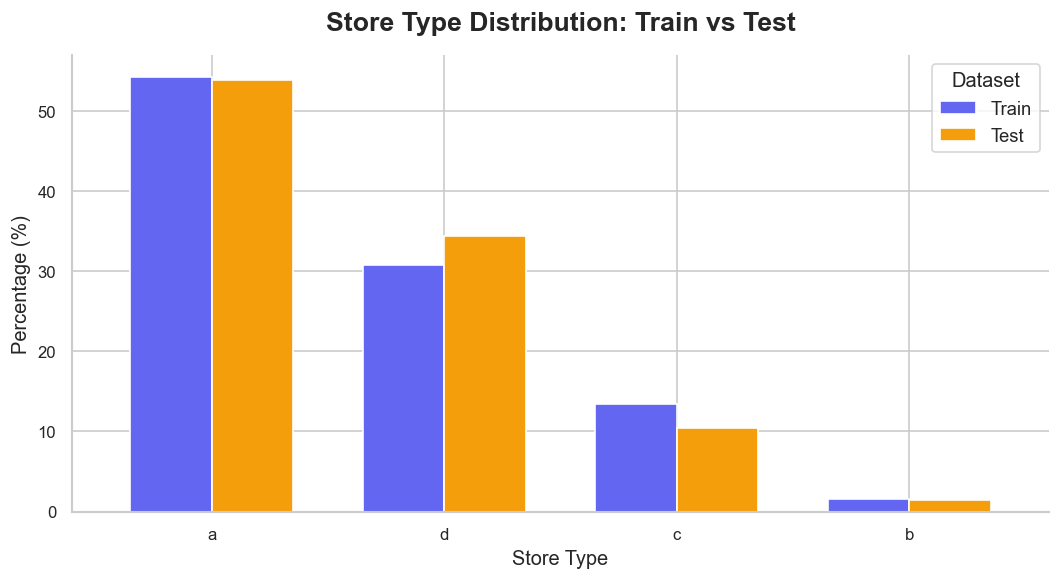

In [59]:
train_storetype = train_df["StoreType"].value_counts(normalize=True)
test_storetype = test_df["StoreType"].value_counts(normalize=True)

storetype_comparison = pd.DataFrame({
    "Train": train_storetype,
    "Test": test_storetype
}).fillna(0) * 100

storetype_comparison.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#6366F1", "#F59E0B"],
    width=0.7
)

plt.title("Store Type Distribution: Train vs Test", pad=15)
plt.xlabel("Store Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

### Insight
+ The distribution of store types is compared across both datasets. Similar percentages indicate that the store-type composition is consistent between training and testing data.
+ This is useful because the model will encounter a similar mix of store categories during prediction.
+ A large difference in distribution could indicate a potential difference between the training and test datasets.

### Compare DayOfWeek Distribution

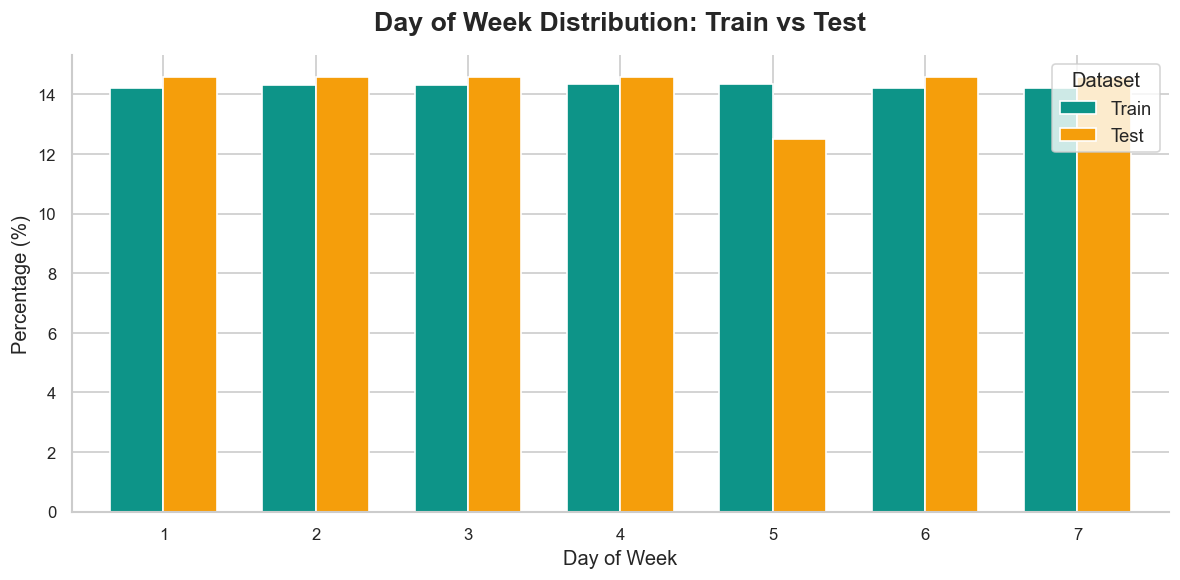

In [60]:
train_day = train_df["DayOfWeek"].value_counts(normalize=True).sort_index()
test_day = test_df["DayOfWeek"].value_counts(normalize=True).sort_index()

day_comparison = pd.DataFrame({
    "Train": train_day,
    "Test": test_day
}).fillna(0) * 100

day_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#0D9488", "#F59E0B"],
    width=0.7
)

plt.title("Day of Week Distribution: Train vs Test", pad=15)
plt.xlabel("Day of Week")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Dataset")

plt.tight_layout()
plt.show()
logger.info("Train and Test comparison analysis completed")

### Insight
- The plot compares the distribution of weekdays across training and testing records.
- Similar distributions suggest that the test dataset contains a weekday composition comparable to the training dataset.
- This is important because sales patterns vary by day of the week.
- Day-of-week information should therefore be retained as an important time-related feature.

## Correlation Analysis

### Numerical Correlation Heatmap

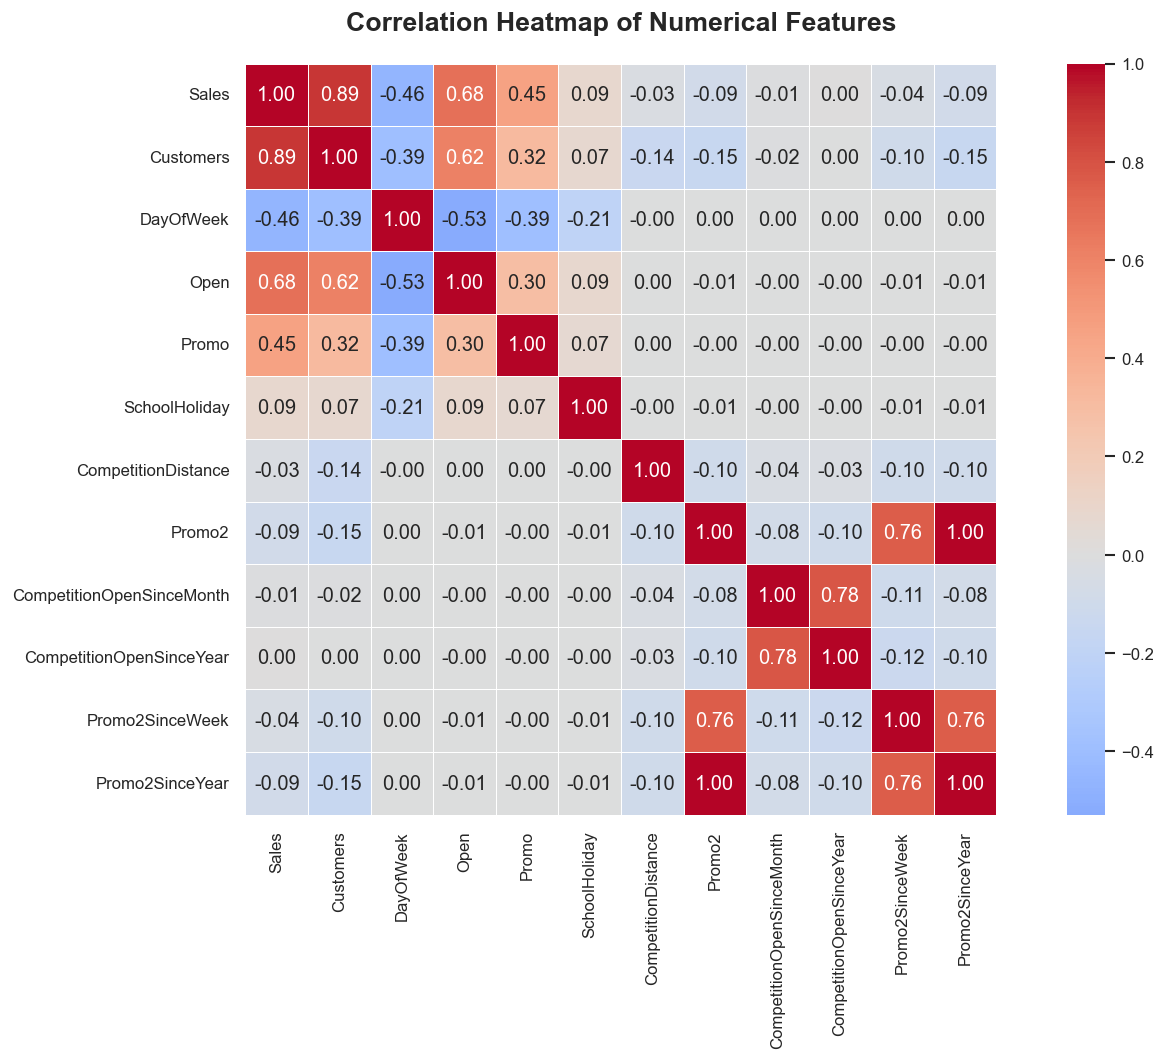

In [61]:
numeric_columns = [
    "Sales",
    "Customers",
    "DayOfWeek",
    "Open",
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "Promo2",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2SinceWeek",
    "Promo2SinceYear"
]

# Keep only columns available in the dataset
numeric_columns = [
    col for col in numeric_columns
    if col in train_df.columns
]

correlation_data = train_df[numeric_columns].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Numerical Features", pad=20)

plt.tight_layout()
plt.show()
logger.info("Correlation analysis completed")

### Insight
+ The heatmap provides an overview of the relationships between numerical variables.
+ Sales and Customers show a strong positive correlation of 0.89, consistent with the separate correlation analysis.
+ Promotional activity also shows an association with sales, indicating that promotional days tend to have higher sales.
+ Correlation values help identify potentially useful features and relationships between variables.
+ However, correlation does not establish causation, and low correlation does not necessarily mean that a feature is unimportant for forecasting.
+ Features such as dates, weekdays, holidays, and promotional indicators may have predictive value even if their linear correlation with sales is relatively low.

## Top 10 Stores by Average Sales

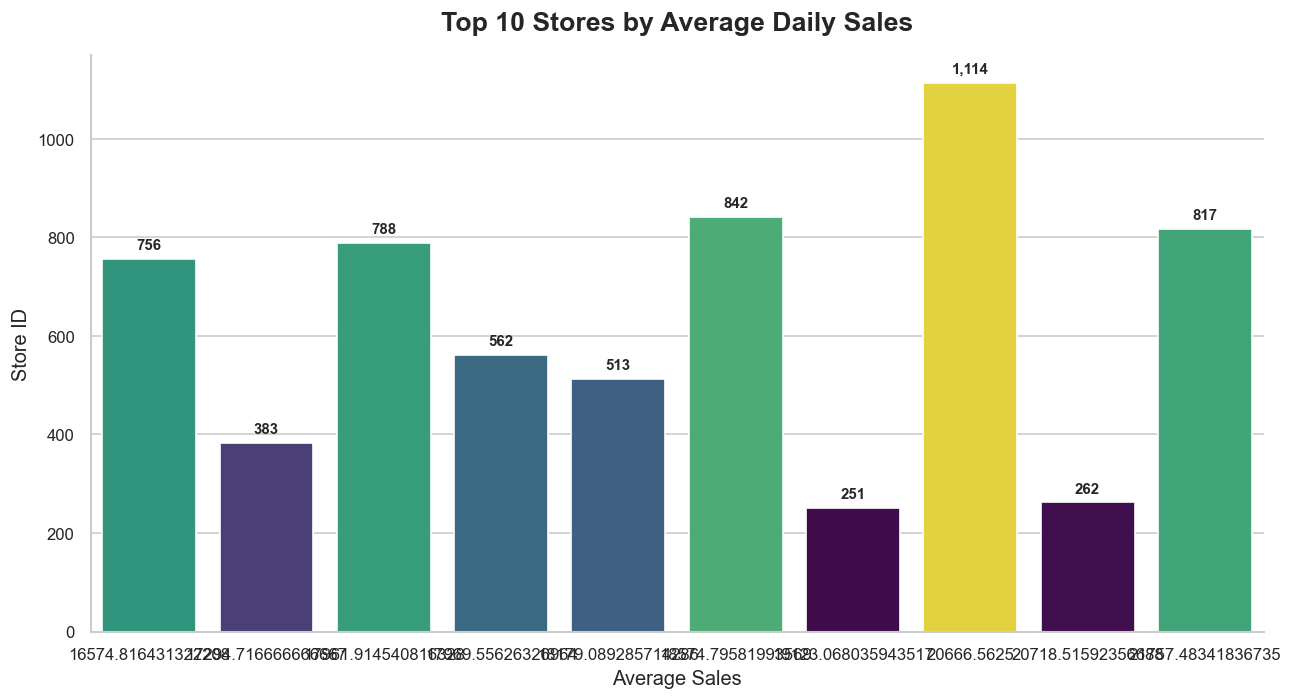

In [62]:

top_stores = (
    open_train.groupby("Store")["Sales"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_stores,
    x="Sales",
    y="Store",
    hue="Store",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Top 10 Stores by Average Daily Sales", pad=15)
plt.xlabel("Average Sales")
plt.ylabel("Store ID")

plt.tight_layout()
plt.show()

### Insight
+ The plot identifies the ten stores with the highest average daily sales among their open-store observations.
+ These stores demonstrate strong average sales performance during the observed period.
+ Comparing these stores can help identify high-performing locations within the Rossmann network.
+ Average sales are useful for comparing daily performance without allowing the total number of recorded days to dominate the ranking.

## Top 10 Stores by Average Customers

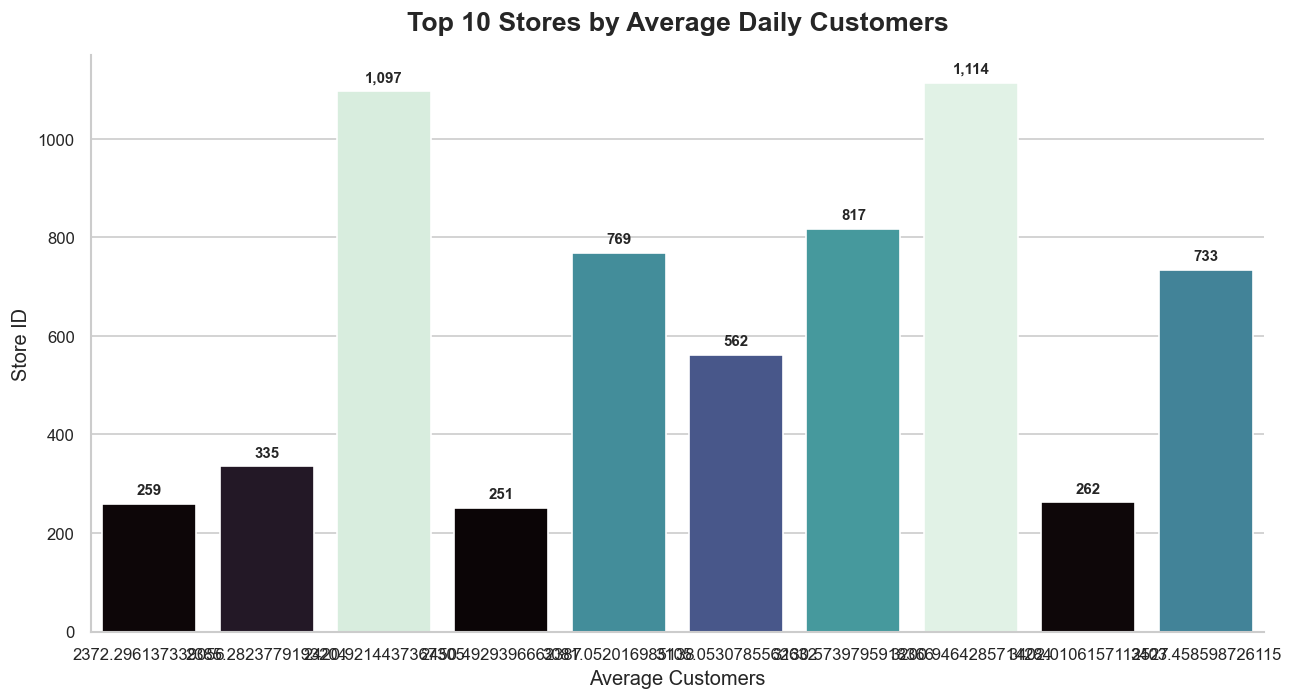

In [63]:
top_customer_stores = (
    open_train.groupby("Store")["Customers"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_customer_stores,
    x="Customers",
    y="Store",
    hue="Store",
    palette="mako",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Top 10 Stores by Average Daily Customers", pad=15)
plt.xlabel("Average Customers")
plt.ylabel("Store ID")

plt.tight_layout()
plt.show()

### Insight
+ The plot identifies stores with the highest average customer footfall.
+ These stores attract a comparatively larger number of customers on a typical open day.
+ Higher customer footfall may contribute to higher sales, as supported by the strong positive correlation between customers and sales.
+ Comparing this ranking with the top stores by average sales can help identify whether high customer traffic corresponds to high revenue.

## Top 10 Stores by Total Sales

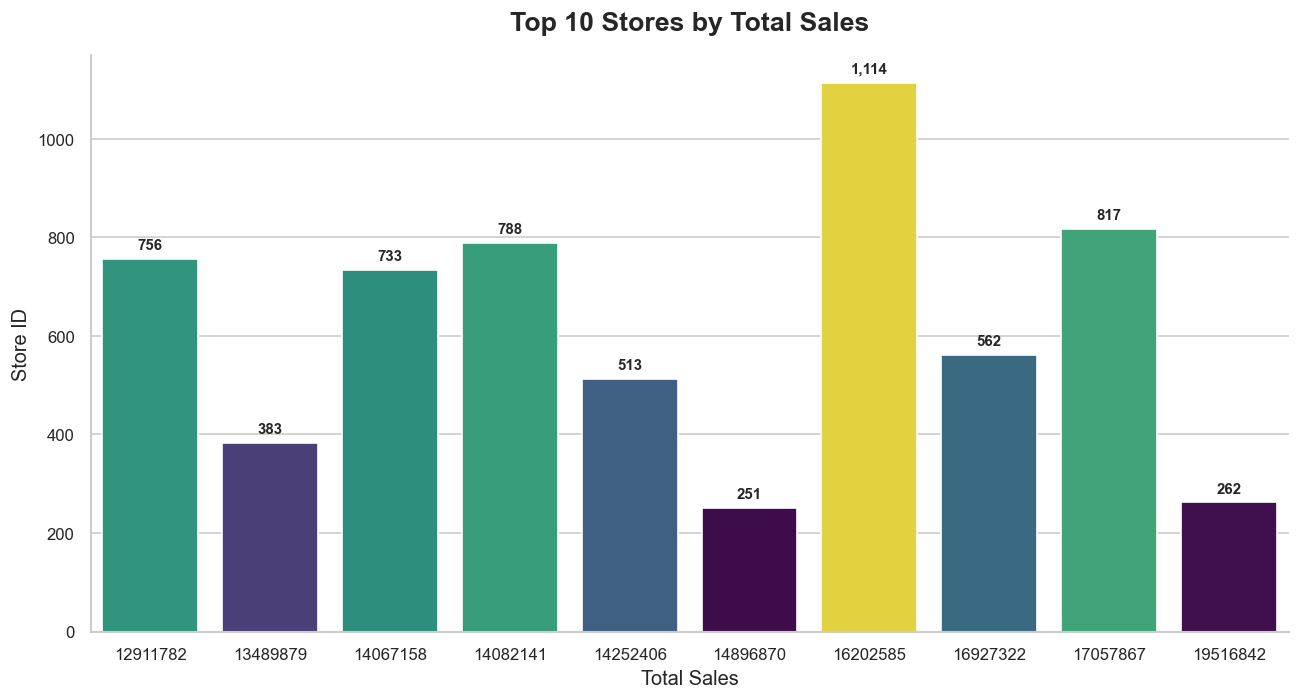

In [64]:
top_total_sales = (
    open_train.groupby("Store")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_total_sales,
    x="Sales",
    y="Store",
    hue="Store",
    palette="viridis",
    legend=False
)

add_bar_labels(ax, fmt="{:,.0f}")

plt.title("Top 10 Stores by Total Sales", pad=15)
plt.xlabel("Total Sales")
plt.ylabel("Store ID")

plt.tight_layout()
plt.show()

### Insight
+ The plot identifies the ten stores generating the highest cumulative sales during the training period.
+ These stores contribute substantially to the overall sales of the business.
+ Total sales depend on both daily sales performance and the number of days a store is open and recorded. Therefore, the ranking may differ from the top ten stores by average daily sales.

## Sales Behaviour Before, During & After Holidays

In [65]:
# Identify holiday dates

holiday_dates = (
    train_df[train_df["StateHoliday"].astype(str) != "0"]["Date"]
    .drop_duplicates()
    .sort_values()
)

print("Number of holiday dates:", len(holiday_dates))
print(holiday_dates.head(10))

Number of holiday dates: 37
1016095   2013-01-01
1010532   2013-01-06
919090    2013-03-29
915745    2013-04-01
882295    2013-05-01
873375    2013-05-09
861110    2013-05-20
849960    2013-05-30
764117    2013-08-15
709470    2013-10-03
Name: Date, dtype: datetime64[ns]


In [66]:
# Create before, during & after holiday categories

holiday_dates_set = set(holiday_dates)

before_dates = {d - pd.Timedelta(days=1) for d in holiday_dates_set}
after_dates = {d + pd.Timedelta(days=1) for d in holiday_dates_set}

open_train["Holiday_Period"] = np.select(
    [
        open_train["Date"].isin(holiday_dates_set),
        open_train["Date"].isin(before_dates),
        open_train["Date"].isin(after_dates)
    ],
    [
        "During Holiday",
        "Before Holiday",
        "After Holiday"
    ],
    default="Normal Days"
)

In [67]:
# Calculate average sales & customers

holiday_analysis = (
    open_train.groupby("Holiday_Period")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum"),
        Total_Customers=("Customers", "sum"),
        Record_Count=("Sales", "count")
    )
    .round(2)
)

holiday_analysis

,Average_Sales,Average_Customers,Total_Sales,Total_Customers,Record_Count
Holiday_Period,,,,,
After Holiday,"7,643.20",836.05,268329956,29351328,35107
Before Holiday,"7,577.97",815.72,205772090,22150082,27154
During Holiday,"7,728.29",893.80,71053868,8217631,9194
Normal Days,"6,893.22",755.98,5328024709,584322714,772937


### Visualize Average Sales

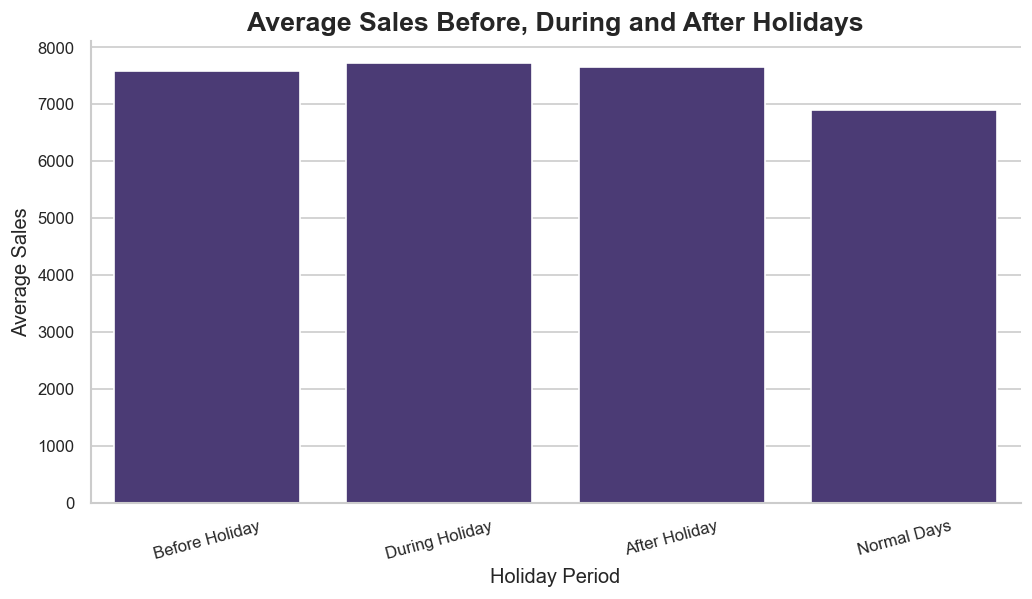

In [68]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=open_train,
    x="Holiday_Period",
    y="Sales",
    order=[
        "Before Holiday",
        "During Holiday",
        "After Holiday",
        "Normal Days"
    ],
    estimator="mean",
    errorbar=None
)

plt.title("Average Sales Before, During and After Holidays")
plt.xlabel("Holiday Period")
plt.ylabel("Average Sales")
plt.xticks(rotation=15)
plt.show()

### Visualize Average Customers

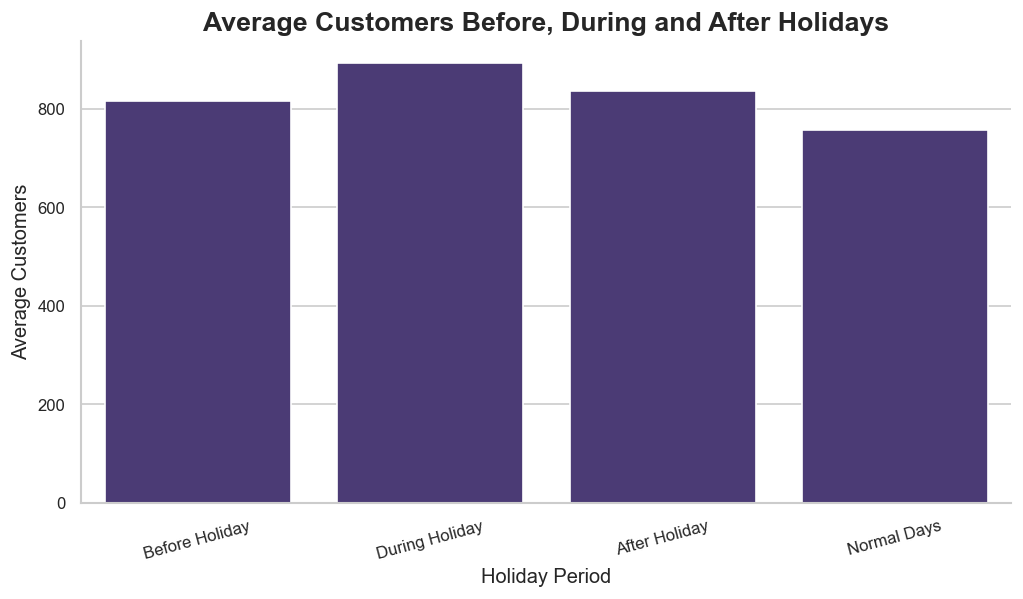

In [69]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=open_train,
    x="Holiday_Period",
    y="Customers",
    order=[
        "Before Holiday",
        "During Holiday",
        "After Holiday",
        "Normal Days"
    ],
    estimator="mean",
    errorbar=None
)

plt.title("Average Customers Before, During and After Holidays")
plt.xlabel("Holiday Period")
plt.ylabel("Average Customers")
plt.xticks(rotation=15)
plt.show()
logger.info("Sales before, during & after holiday analysis completed")

### Insight
+ Average sales are highest during holidays (7,728.29), followed by after holidays (7,643.20) and before holidays (7,577.97).
+ Sales during holidays are approximately 12.1% higher than on normal days.
+ Customer footfall is also highest during holidays, averaging approximately 894 customers compared with 756 on normal days.
+ Both sales and customer numbers remain higher than normal levels before and after holidays, suggesting increased purchasing activity around holiday periods.
+ Overall, holiday periods are associated with increased customer activity and sales compared with normal days.

## Seasonal Purchasing Behaviour

In [70]:
# Extract christmas and easter records

seasonal_data = open_train.copy()

seasonal_data["Holiday_Type"] = seasonal_data["StateHoliday"].astype(str)

seasonal_data["Season"] = np.select(
    [
        seasonal_data["Holiday_Type"] == "c",
        seasonal_data["Holiday_Type"] == "b"
    ],
    [
        "Christmas",
        "Easter"
    ],
    default="Other Days"
)

### Compare Average Sales

In [71]:
seasonal_sales = (
    seasonal_data.groupby("Season")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum")
    )
    .round(2)
)

seasonal_sales

,Average_Sales,Average_Customers,Total_Sales
Season,,,
Christmas,"9,743.75","1,569.23",691806
Easter,"9,887.89","1,686.89",1433744
Other Days,"6,954.78",762.50,5871055073


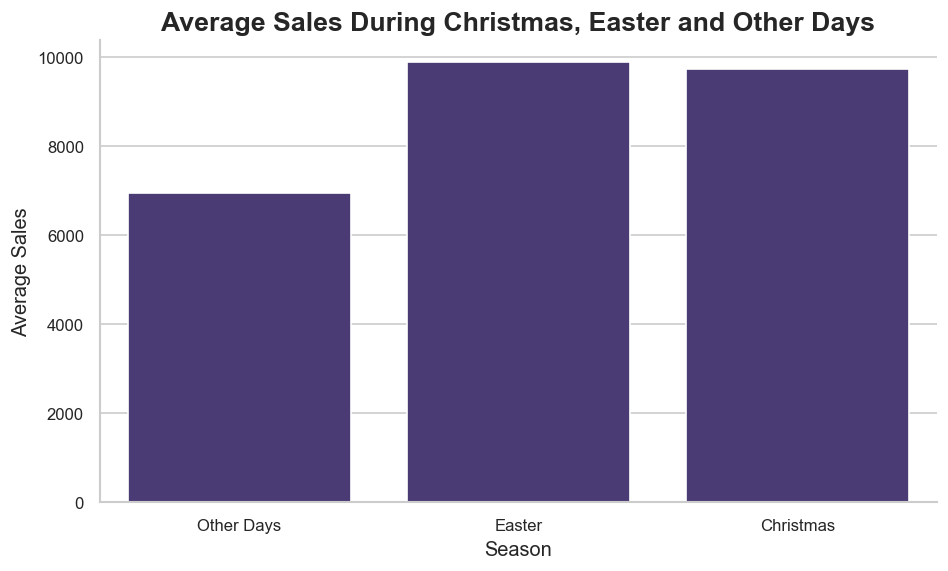

In [72]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=seasonal_data,
    x="Season",
    y="Sales",
    estimator="mean",
    errorbar=None
)

plt.title("Average Sales During Christmas, Easter and Other Days")
plt.xlabel("Season")
plt.ylabel("Average Sales")
plt.show()

### Insight
+ Easter records the highest average sales (9,887.89), slightly higher than Christmas (9,743.75).
+ Both Christmas and Easter show considerably higher average sales than other days.
+ Average sales during Easter are approximately 42.2% higher than on other days, while Christmas sales are approximately 40.1% higher.

### Compare Customer Numbers

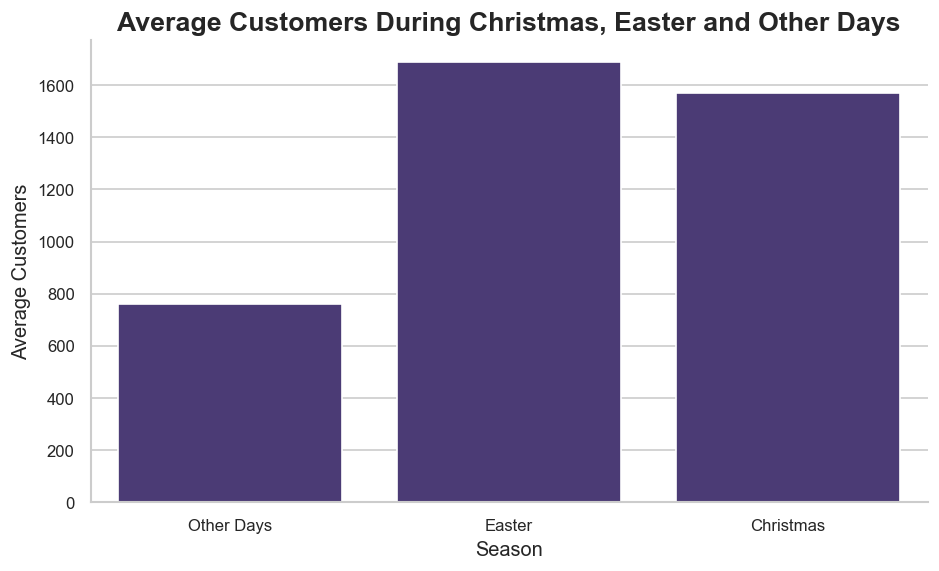

In [73]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=seasonal_data,
    x="Season",
    y="Customers",
    estimator="mean",
    errorbar=None
)

plt.title("Average Customers During Christmas, Easter and Other Days")
plt.xlabel("Season")
plt.ylabel("Average Customers")
plt.show()

### Insight
+ Customer footfall increases substantially during both seasonal periods. Easter records approximately 1,687 customers and Christmas approximately 1,569, compared with 763 on other days.
+ These results indicate stronger purchasing activity during Christmas and Easter periods, with Easter showing the highest average sales and customer footfall.

### Analyse Days Surrounding Christmas and Easter

In [74]:
christmas_dates = set(
    train_df.loc[
        train_df["StateHoliday"].astype(str) == "c",
        "Date"
    ].unique()
)

easter_dates = set(
    train_df.loc[
        train_df["StateHoliday"].astype(str) == "b",
        "Date"
    ].unique()
)

def get_seasonal_window(date, holiday_dates):
    for holiday_date in holiday_dates:
        difference = (date - holiday_date).days

        if -7 <= difference <= 7:
            if difference < 0:
                return "Before Holiday"
            elif difference == 0:
                return "During Holiday"
            else:
                return "After Holiday"

    return "Outside Holiday Window"

In [75]:
# For Christmas

christmas_data = open_train.copy()

christmas_data["Christmas_Period"] = christmas_data["Date"].apply(
    lambda x: get_seasonal_window(x, christmas_dates)
)

christmas_data.groupby("Christmas_Period").agg(
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean")
).round(2)

,Average_Sales,Average_Customers
Christmas_Period,,
After Holiday,"6,616.18",748.95
Before Holiday,"9,724.93",990.46
During Holiday,"9,029.42","1,468.88"
Outside Holiday Window,"6,918.14",759.45


### Insight
+ Average sales are highest in the seven days before Christmas (9,724.93), indicating increased purchasing activity ahead of the holiday.
+ Customer footfall is highest during Christmas (approx 1,469), although average sales are slightly lower than before Christmas.
+ After Christmas, average sales decrease to 6,616.18, below the average recorded outside the Christmas window.
+ The increase in customer activity before and during Christmas suggests stronger shopping demand around the festive period.

In [106]:
# For Easter

easter_data = open_train.copy()

easter_data["Easter_Period"] = easter_data["Date"].apply(
    lambda x: get_seasonal_window(x, easter_dates)
)

easter_data.groupby("Easter_Period").agg(
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean")
).round(2)
logger.info("Christmas and Easter seasonal analysis completed")

### Insight
+ Average sales are highest during Easter (10,910.88), followed by the days before Easter (8,545.13).
+ Customer footfall increases substantially during Easter, reaching approximately 1,847 customers compared with 759 outside the holiday window.
+ Average sales decrease after Easter to 6,665.89, indicating lower purchasing activity following the holiday.
+ Both sales and customer numbers show increased activity around Easter, with the strongest customer footfall occurring during the holiday.

### Overall seasonal insight: 
+ Christmas and Easter periods are associated with increased sales and customer visits. The results suggest that stores may experience stronger demand before and during these festive periods, making them important periods for inventory and promotional planning.

## Promotion Effectivness by Individual Stores

### Compare Promo and Non-Promo Sales for Each Store

In [86]:
store_promo_pivot = (
    open_train.groupby(["Store", "Promo"])
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Number_of_Days=("Sales", "count")
    )
    .unstack("Promo")
)

# Flatten MultiIndex columns
store_promo_pivot.columns = [
    f"{metric}_{'No_Promo' if promo == 0 else 'Promo'}"
    for metric, promo in store_promo_pivot.columns
]

# Convert Store index into a column
store_promo_pivot = store_promo_pivot.reset_index()


### Calculate Promotion Lift

In [87]:
store_promo_pivot["Sales_Lift_Percentage"] = (
    (
        store_promo_pivot["Average_Sales_Promo"] -
        store_promo_pivot["Average_Sales_No_Promo"]
    ) /
    store_promo_pivot["Average_Sales_No_Promo"].replace(0, np.nan)
) * 100

store_promo_pivot["Customer_Lift_Percentage"] = (
    (
        store_promo_pivot["Average_Customers_Promo"] -
        store_promo_pivot["Average_Customers_No_Promo"]
    ) /
    store_promo_pivot["Average_Customers_No_Promo"].replace(0, np.nan)
) * 100

store_promo_pivot = store_promo_pivot.round(2)

store_promo_pivot.head()

,Store,Average_Sales_No_Promo,Average_Sales_Promo,Average_Customers_No_Promo,Average_Customers_Promo,Number_of_Days_No_Promo,Number_of_Days_Promo,Sales_Lift_Percentage,Customer_Lift_Percentage
0,1,"4,319.76","5,300.11",539.71,594.02,431,350,22.69,10.06
1,2,"3,864.29","6,277.44",496.56,690.21,430,354,62.45,39.00
2,3,"5,382.61","8,854.63",647.72,875.53,429,350,64.50,35.17
3,4,"8,870.35","10,576.16","1,265.32","1,390.65",431,353,19.23,9.91
4,5,"3,511.41","6,096.68",442.07,653.52,428,351,73.63,47.83


### Top 10 Stores with Highest Sales Lift

In [88]:
eligible_stores = store_promo_pivot[
    (store_promo_pivot["Number_of_Days_Promo"] >= 10) &
    (store_promo_pivot["Number_of_Days_No_Promo"] >= 10)
].copy()

top_promo_stores = eligible_stores.sort_values(
    by="Sales_Lift_Percentage",
    ascending=False
).head(10)

top_promo_stores[
    ["Store", "Sales_Lift_Percentage", "Customer_Lift_Percentage"]
]

,Store,Sales_Lift_Percentage,Customer_Lift_Percentage
197,198,144.93,87.32
606,607,117.24,73.87
542,543,110.16,60.10
574,575,109.89,68.57
692,693,98.95,60.75
270,271,97.09,63.85
551,552,95.21,51.73
95,96,93.70,60.44
634,635,93.51,63.23
488,489,93.47,57.26


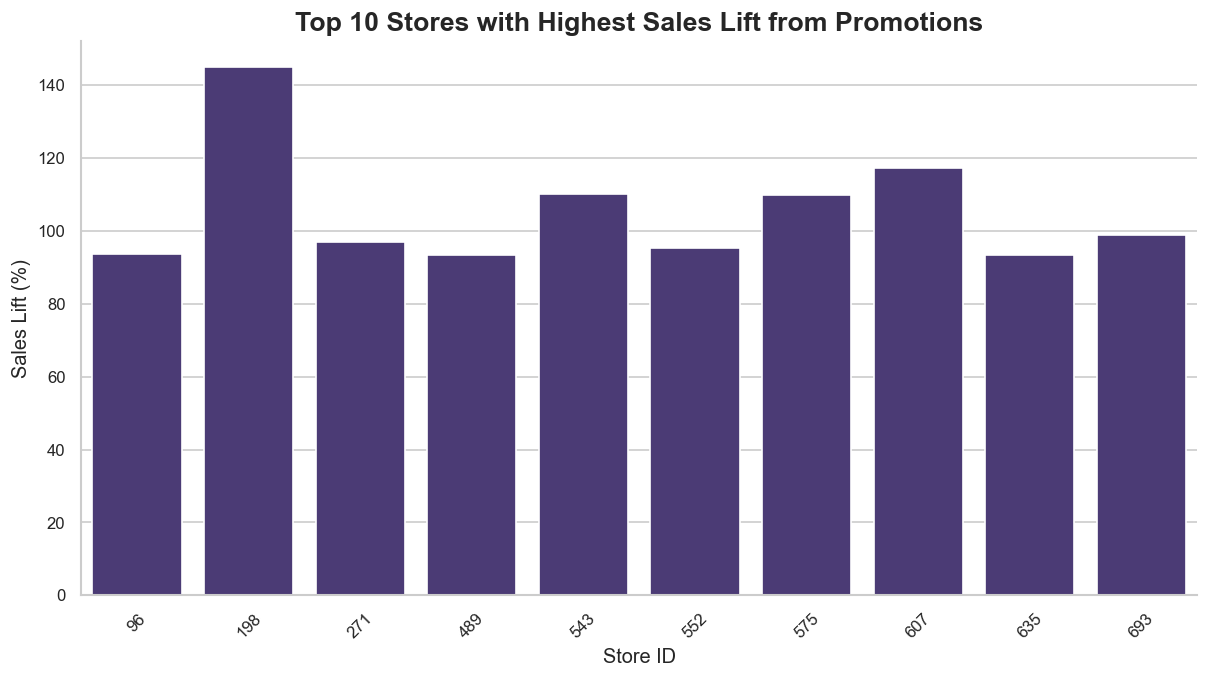

In [89]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_promo_stores,
    x="Store",
    y="Sales_Lift_Percentage",
    errorbar=None
)

plt.title("Top 10 Stores with Highest Sales Lift from Promotions")
plt.xlabel("Store ID")
plt.ylabel("Sales Lift (%)")
plt.xticks(rotation=45)
plt.show()

### Insight
+ Store 198 records the highest sales lift of approximately 144.93%, followed by Store 607 at 117.24%.
+ All ten top-performing stores show positive sales and customer lift during promotional periods.
+ Store 198 also records an 87.32% increase in customer footfall, suggesting that promotions are associated with both higher sales and increased customer visits.
+ Stores such as 543, 575, and 693 also show substantial improvements in sales and customer activity.
+ These stores may be suitable candidates for further investigation when planning promotional campaigns.

### Identify Stores with Lowest Sales Lift

In [90]:
low_promo_stores = eligible_stores.sort_values(
    by="Sales_Lift_Percentage",
    ascending=True
).head(10)

low_promo_stores[
    ["Store", "Sales_Lift_Percentage", "Customer_Lift_Percentage"]
]

,Store,Sales_Lift_Percentage,Customer_Lift_Percentage
273,274,-6.95,-4.73
261,262,2.15,-3.37
947,948,2.71,7.24
826,827,3.24,-3.97
552,553,3.53,-7.26
352,353,4.49,5.77
443,444,5.07,-6.27
759,760,5.38,0.10
675,676,5.54,9.56
1074,1075,6.27,3.40


### Insight
- Store 274 records a negative sales lift of -6.95% and a negative customer lift of -4.73%, indicating lower average sales and customer visits during promotional periods.
- Several stores show positive sales lift but negative customer lift, suggesting that increased sales do not necessarily correspond to increased customer traffic.
- Store 553 records a positive sales lift of 3.53% but a negative customer lift of -7.26%.
- The results indicate that promotional effectiveness differs considerably across stores.
- Stores with low or negative promotional lift may require a review of their promotional strategies.

### Compare Customer and Sales Lift

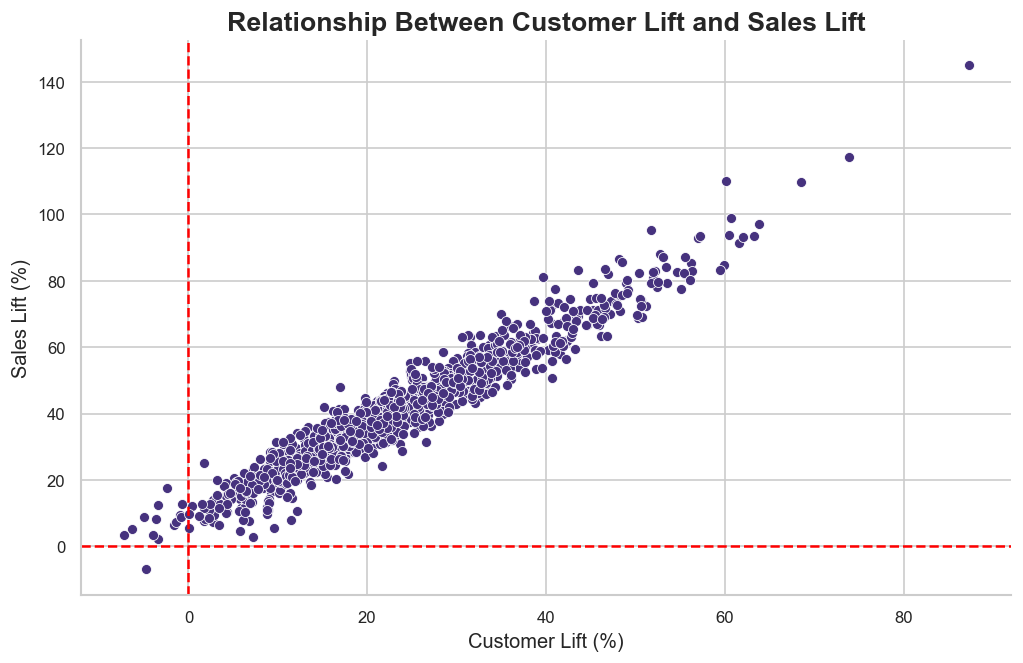

In [91]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=eligible_stores,
    x="Customer_Lift_Percentage",
    y="Sales_Lift_Percentage"
)

plt.axhline(0, linestyle="--", color="red")
plt.axvline(0, linestyle="--", color="red")

plt.title("Relationship Between Customer Lift and Sales Lift")
plt.xlabel("Customer Lift (%)")
plt.ylabel("Sales Lift (%)")
plt.show()
logger.info("Promotion lift analysis completed")

### Insight
+ Most stores with higher customer lift also show higher sales lift.
+ Stores in the positive sales and customer lift region demonstrate better promotional performance.
+ Some stores show differences between sales lift and customer lift, indicating that promotions may influence average spending and customer traffic differently.
+ This suggests that promotional strategies should be evaluated at individual store level rather than applied uniformly.

## Stores Opening and Closing Pattern

### Count Open and Closed Stores by Weekday

In [92]:
opening_analysis = train_df.copy()

opening_analysis["Day_Name"] = (
    opening_analysis["Date"].dt.day_name()
)

opening_summary = (
    opening_analysis.groupby(["Day_Name", "Open"])
    .size()
    .unstack(fill_value=0)
)

opening_summary = opening_summary.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

opening_summary

Open,0,1
Day_Name,,
Monday,7170,137560
Tuesday,1703,143961
Wednesday,3729,141936
Thursday,11201,134644
Friday,7205,138640
Saturday,672,144058
Sunday,141137,3593


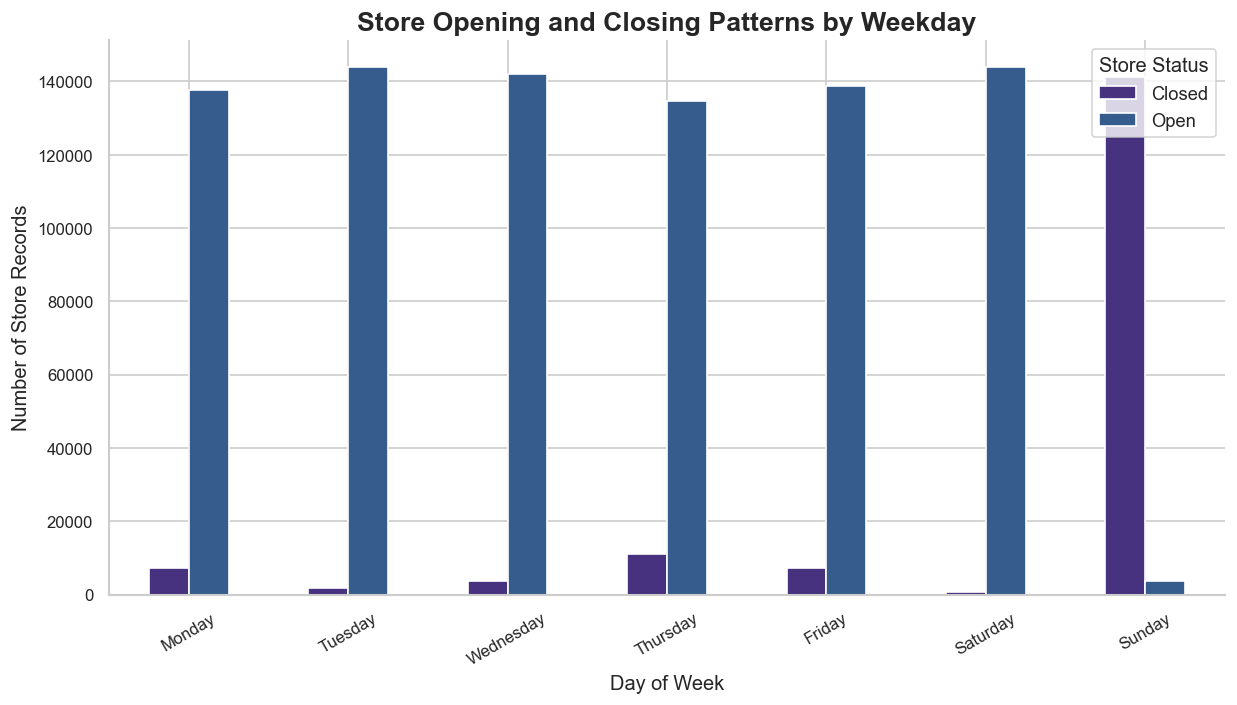

In [93]:
# Visualization

opening_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Store Opening and Closing Patterns by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of Store Records")
plt.xticks(rotation=30)
plt.legend(["Closed", "Open"], title="Store Status")
plt.show()

In [94]:
# caculate openinng percentage for each weekday
opening_summary["Total"] = (
    opening_summary[0] + opening_summary[1]
)

opening_summary["Opening_Percentage"] = (
    opening_summary[1] / opening_summary["Total"] * 100
)

opening_summary[["Opening_Percentage"]].round(2)

Open,Opening_Percentage
Day_Name,
Monday,95.05
Tuesday,98.83
Wednesday,97.44
Thursday,92.32
Friday,95.06
Saturday,99.54
Sunday,2.48


### Insight
+ Saturday has the highest store opening percentage at approximately 99.54%, indicating that almost all stores operate on Saturdays.
+ Tuesday and Wednesday also show high opening percentages of 98.83% and 97.44%, respectively.
+ Sunday has the lowest opening percentage at only 2.48%, indicating that the majority of stores remain closed on Sundays.
+ Thursday has a comparatively lower opening percentage of 92.32% among weekdays.
+ Store operating patterns vary considerably across the week, with Sunday showing a particularly high number of closures.

### Stores that Open on all Seven Days

In [95]:
train_df["Day_Name"] = (
    train_df["Date"].dt.day_name()
)

store_weekday_opening = (
    train_df.groupby(["Store", "Day_Name"])["Open"]
    .mean()
    .unstack()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

store_weekday_opening = store_weekday_opening.reindex(
    columns=weekday_order
)

store_weekday_opening.head()

Day_Name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Store,,,,,,,
1,0.96,0.99,0.98,0.92,0.96,1.00,0.00
2,0.96,0.99,0.98,0.94,0.96,1.00,0.00
3,0.96,0.99,0.98,0.92,0.95,0.99,0.00
4,0.96,0.99,0.98,0.94,0.96,1.00,0.00
5,0.95,0.99,0.96,0.93,0.95,1.00,0.00


In [96]:
all_week_open_stores = store_weekday_opening[
    (store_weekday_opening == 1).all(axis=1)
].index.tolist()

print("Number of stores open all 7 days:",
      len(all_week_open_stores))

print("Store IDs:", all_week_open_stores)

Number of stores open all 7 days: 10
Store IDs: [85, 262, 335, 423, 494, 562, 682, 733, 769, 1097]


### Insight
+ Only 10 stores remain open throughout all seven days of the week.
+ These stores record higher average sales on weekdays (12,772.08) than on weekends (11,627.11).
+ Average weekday sales are approximately 9.85% higher than weekend sales.
+ Customer footfall is also higher on weekdays, with approximately 2,409 customers compared with 2,215 on weekends.
+ Although these stores operate throughout the week, their weekend sales and customer traffic are comparatively lower than weekday levels.

In [97]:
# Compare Weekend sales for these stores
weekend_data = open_train.copy()

weekend_data["Day_Name"] = (
    weekend_data["Date"].dt.day_name()
)

weekend_data["Day_Type"] = np.where(
    weekend_data["Day_Name"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday"
)

all_week_open_sales = weekend_data[
    weekend_data["Store"].isin(all_week_open_stores)
]

weekend_sales_summary = (
    all_week_open_sales.groupby("Day_Type")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum")
    )
    .round(2)
)

weekend_sales_summary

,Average_Sales,Average_Customers,Total_Sales
Day_Type,,,
Weekday,"12,772.08","2,408.83",86083827
Weekend,"11,627.11","2,215.32",31160663


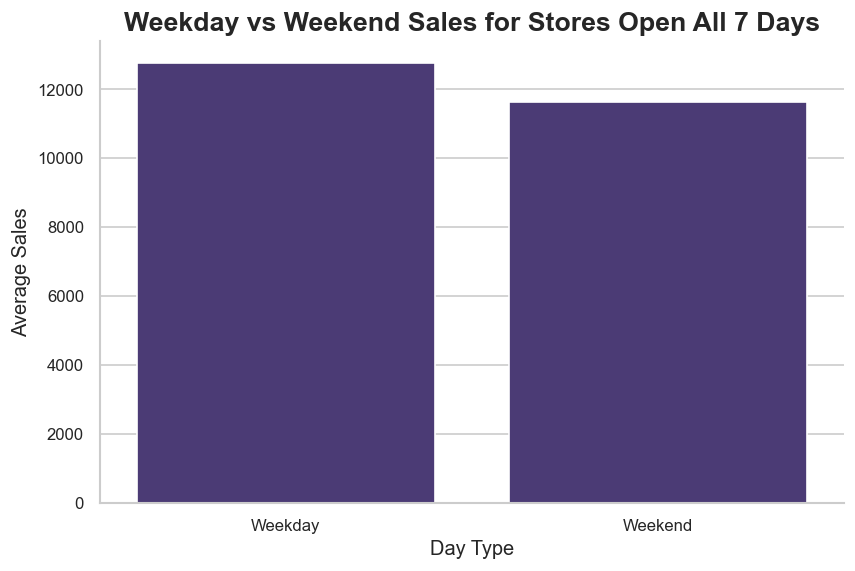

In [98]:
# Weekday vs Weekend Sales
plt.figure(figsize=(8, 5))

sns.barplot(
    data=all_week_open_sales,
    x="Day_Type",
    y="Sales",
    estimator="mean",
    errorbar=None
)

plt.title("Weekday vs Weekend Sales for Stores Open All 7 Days")
plt.xlabel("Day Type")
plt.ylabel("Average Sales")
plt.show()

### Insight
+ Stores that remain open throughout all seven days generate higher average sales on weekdays compared to weekends.
+ Average weekday sales are approximately 12,772, while average weekend sales are approximately 11,627.
+ Weekday sales are around 9.85% higher than weekend sales.
+ This indicates that even stores operating throughout the week experience stronger sales during weekdays.
+ Weekend operations do not necessarily result in higher sales, suggesting that customer purchasing activity may be stronger on regular working days.

### Compare Customer Traffic

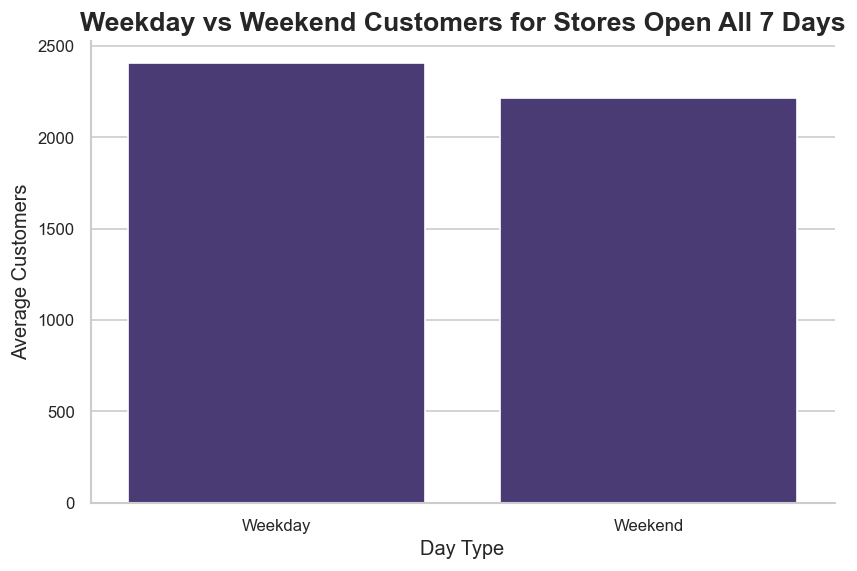

In [99]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=all_week_open_sales,
    x="Day_Type",
    y="Customers",
    estimator="mean",
    errorbar=None
)

plt.title("Weekday vs Weekend Customers for Stores Open All 7 Days")
plt.xlabel("Day Type")
plt.ylabel("Average Customers")
plt.show()
logger.info("Store opening and closing analysis completed")

### Insight
+ Stores operating all seven days attract more customers on weekdays compared to weekends.
+ Average weekday customer footfall is approximately 2,409, compared to 2,215 on weekends.
+ Weekday customer visits are around 8.74% higher than weekend visits.
+ This indicates stronger customer activity during weekdays, even in stores that remain open throughout the week.
+ The higher weekday footfall is consistent with the higher weekday average sales observed in the previous graph.

## Summary Tables for Business Insights

### Sales Summary by StoreType

In [100]:
store_summary = (
    open_train.groupby("StoreType")
    .agg(
        Average_Sales=("Sales", "mean"),
        Total_Sales=("Sales", "sum"),
        Average_Customers=("Customers", "mean"),
        Maximum_Sales=("Sales", "max")
    )
    .round(2)
    .sort_values("Average_Sales", ascending=False)
)

display(store_summary)

,Average_Sales,Total_Sales,Average_Customers,Maximum_Sales
StoreType,,,,
b,"10,231.41",159231395,"2,021.82",38722
c,"6,932.51",783221426,815.47,31448
a,"6,925.17",3165334859,795.36,41551
d,"6,822.14",1765392943,606.34,38037


### Insight
+ Store Type b has the highest average sales of 10,231.41 and average customer footfall of 2,021.82.
+ Store Type a contributes the highest total sales, approximately 3.17 billion, because it has a larger contribution across the dataset. However average sale and average customers for store type a are less than store type b.
+ Store Type d also contributes substantial total sales, despite having lower average sales than Store Type b.
+ This shows that average performance and total business contribution are different measures and should be evaluated separately.

### Sales Summary by DayOfWeek

In [101]:
day_summary = (
    open_train.groupby("DayOfWeek")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum")
    )
    .round(2)
)

display(day_summary)

,Average_Sales,Average_Customers,Total_Sales
DayOfWeek,,,
1,"8,216.07",855.44,1130203012
2,"7,088.11",769.99,1020411930
3,"6,728.12",740.60,954962863
4,"6,767.31",755.57,911177709
5,"7,072.68",781.77,980555941
6,"5,874.84",660.18,846317735
7,"8,224.72","1,441.53",29551433


### Insight
+ Sunday has the highest average sales (8,224.72), closely followed by Monday (8,216.07).
+ Saturday has the lowest average sales (5,874.84) among the seven days.
+ Sunday has only a small number of open-store records compared with other days, so its average is less representative of the entire store network.
+ Monday shows strong average sales and substantially more observations than Sunday.
+ The variation across weekdays confirms that the day of the week is an important feature to consider in sales forecasting.

### Sales Summary by Promotion

In [102]:
promo_summary = (
    open_train.groupby("Promo")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum")
    )
    .round(2)
)

display(promo_summary)

,Average_Sales,Average_Customers,Total_Sales
Promo,,,
0,"5,929.41",696.86,2771974337
1,"8,228.28",844.43,3101206286


### Insight
+ Average sales increase from 5,929.41 without promotions to 8,228.28 with promotions.
+ Average customers also increase from approximately 697 to 844 on promotional days.
+ Promotional records contribute approximately 3.10 billion in total sales, compared with approximately 2.77 billion for non-promotional records.
+ These findings indicate a positive association between promotional activity, customer footfall, and sales performance.

### Sales Summary by Assortment

In [103]:
assortment_summary = (
    open_train.groupby("Assortment")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum")
    )
    .round(2)
)

display(assortment_summary)
logger.info("Summary table completed")

,Average_Sales,Average_Customers,Total_Sales
Assortment,,,
a,"6,621.02",747.94,2945750070
b,"8,639.35","2,066.80",70946312
c,"7,300.53",752.17,2856484241


### Insight
+ Assortment b has the highest average sales (6,621.02) and average customers (approx 748).
+ Assortment c generates higher average sales than Assortment a.
+ Assortment a contributes the highest total sales, approximately 2.95 billion, while Assortment c contributes approximately 2.86 billion.
+ The difference between average and total sales highlights the importance of considering both store performance and the number of observations in each category.

In [104]:
print("========== KEY EDA STATISTICS ==========")

print("\n1. Average Sales:")
print(round(open_train["Sales"].mean(), 2))

print("\n2. Average Customers:")
print(round(open_train["Customers"].mean(), 2))

print("\n3. Highest Average Sales Day:")
print(
    day_summary["Average_Sales"].idxmax()
)

print("\n4. Highest Average Sales Store Type:")
print(
    store_summary["Average_Sales"].idxmax()
)

print("\n5. Highest Average Sales Promotion Status:")
print(
    promo_summary["Average_Sales"].idxmax()
)

print("\n6. Highest Average Sales Assortment:")
print(
    assortment_summary["Average_Sales"].idxmax()
)

print("\n7. Sales-Customer Correlation:")
print(
    round(
        open_train[["Sales", "Customers"]].corr().iloc[0, 1],
        3
    )
)

print("\n========================================")
logger.info("EDA process completed successfully")

========== KEY EDA STATISTICS ==========

1. Average Sales:
6955.51

2. Average Customers:
762.73

3. Highest Average Sales Day:
7

4. Highest Average Sales Store Type:
b

5. Highest Average Sales Promotion Status:
1

6. Highest Average Sales Assortment:
b

7. Sales-Customer Correlation:
0.824



## Key Findings and Business Insights
1. Sales distribution: Daily sales vary considerably across stores and dates. Most observations fall within a common sales range, while a smaller number of observations have exceptionally high sales.

2. Customer behaviour: There is a strong positive correlation of approximately 0.824 between customer footfall and sales, indicating that customer traffic is an important factor associated with revenue.

3. Promotional impact: Average sales are higher on promotional days (8,228.28) compared with non-promotional days (5,929.41). Promotional activity is also associated with higher customer footfall. Promotional performance varies significantly between stores. Store 198 records the highest sales lift of 144.93%, while Store 274 records a negative sales lift of -6.95%.

4. Store type performance: Store Type b has the highest average sales (10,231.41) and average customer count (2,021.82), making it the strongest category in terms of average daily performance.

5. Assortment performance: Assortment b records the highest average sales (8,639.35), followed by Assortment c and Assortment a.

6. Weekly patterns: Sales vary across weekdays. Monday and Sunday show the highest average values in the summary, but Sunday has considerably fewer open-store observations, so its average requires careful interpretation. Stores open throughout the week generate higher average sales and customer visits on weekdays than weekends.

7. Seasonality: Monthly and yearly comparisons indicate the importance of examining seasonal and time-based patterns when forecasting sales.

8. Seasonal purchasing behaviour: Christmas and Easter show substantially higher sales and customer visits than other days. Easter records the highest average sales and customer footfall.

9. Christmas and Easter windows: Customer activity increases considerably around both festive periods, while sales and customer numbers decline after the holidays.

10.  Holiday effects: State holidays and school holidays provide additional information about changes in customer activity and sales patterns. Average sales and customer footfall are higher before, during, and after holidays compared with normal days, with the highest average sales and customer activity occurring during holidays.

11.  Competition: Competition distance varies considerably between stores. However, distance alone does not fully explain differences in sales performance.

12.   Promo2: More than half of the stores participate in Promo2, and promotional intervals provide additional information about recurring promotional campaigns.

13.    Store-level variation: The top-performing stores differ in average sales, customer footfall, and total sales, showing that individual store characteristics are important.

14. Store opening patterns: Saturday has the highest opening percentage, whereas Sunday has the lowest. Only 10 stores are identified as operating throughout all seven days.

15.  Forecasting relevance: Date-related variables, promotions, holidays, store type, assortment, and competition-related information are useful features to investigate during model development.